# §9 Robustness and Credibility (Stage S9)

§7 reached its verdicts on one set of folds, one label definition, one imputation rule and one
regularisation strength. This section asks how much of that is **procedure** and how much is **data**:

* **controls** – does the evaluation produce AUC 0.5 when there is nothing to find (label permutation,
  pure-noise feature), and does it find a signal of known size (positive control)?
* **stability** – does the headline comparison S − M1 keep its verdict under other CV seeds, 16
  pre-specified analysis variations, a 60-specification curve, survey-cluster folds and a
  missing-not-at-random scenario for HbA1c?
* **external validity** – do our population numbers line up with the published NCHS Data Brief 516?
* **leak hunt (loop L3)** – could any admissible feature be a disguised label?
* **hold-out** – the 20 % hold-out is evaluated **once**, only after the `exp-freeze` tag.

All work before section 11 uses the training part only (4,584 rows). Headline comparison throughout:
ΔAUC(S − M1), the "minimal vs systematic" contrast of hypothesis H2b(a) (locked rule: *supported* =
equivalence within ±0.01; §7 verdict *inconclusive*).

Contents: 1 reference · 2 controls · 3 seeds · 4 sensitivity table · 5 specification curve · 6 survey-cluster
CV · 7 missing HbA1c (IPW, delta) · 8 external validity · 9 leak hunt · 10 pre-hold-out summary ·
11 one-shot hold-out · 12 storage

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek, survey as sv, robustness as RB
from src.robustness import Spec

pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 60)
warnings.filterwarnings("ignore", category=UserWarning)
os.environ.setdefault("PYTHONWARNINGS", "ignore")
OUT = C.RESULTS_DIR / "S9"
OUT.mkdir(parents=True, exist_ok=True)
N_JOBS = min(16, max(1, (os.cpu_count() or 2) - 2))
T_START = time.time()
S9 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_perm": C.N_PERM,
      "n_boot_coef": C.N_BOOT_COEF}
OI = C.OKABE_ITO
S7m = R.load_section("S7")
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, permutations = {C.N_PERM}, {N_JOBS} workers")

mode FINAL: 5x5 CV, B = 1000, permutations = 100, 16 workers


## 1 Reference comparison
**Why.** Every robustness check varies one thing against a fixed reference, so the reference must be
exactly the §7 run: same training part, same stored folds, frozen C0, same comparison engine
(`robustness.compare` mirrors the §7 engine: Nadeau–Bengio corrected t and paired bootstrap, wider interval on
E-ALL; bootstrap only on E-SCREEN).

In [2]:
ctx = RB.load_context()
RUNS = {}                                              # cache: (Spec, folds hash) -> OOF frame
hold = json.loads((C.RESULTS_DIR / "splits" / "holdout.json").read_text(encoding="utf-8"))
assert ctx.folds.hash == S7m["splits"]["folds_hash"] or not C.IS_FINAL, "FINAL run must use the S7 folds"
assert hold["sha256_test_seqn"] == S7m["splits"]["holdout_sha256"]
print(f"training part {ctx.n:,} rows, {ctx.y.sum()} L_comb positives; E-SCREEN {ctx.esc.sum():,} rows, "
      f"{ctx.y_esc[ctx.esc].sum()} positives; folds {len(ctx.folds)} ({ctx.folds.path.name}, hash {ctx.folds.hash[:12]}...)")
print(f"frozen C0 = {ctx.C0}; hold-out {len(ctx.test_idx):,} rows (SHA-256 {hold['sha256_test_seqn'][:16]}...) not read here")

def pair(spec_a, spec_b, folds=None, *, tag, label="L_comb", rows=None, use_t=True, w=None):
    """Run two specs (cached) and compare A - B on E-ALL (label) and E-SCREEN; returns two rows."""
    folds = ctx.folds if folds is None else folds
    oof = RB.run_many(ctx, {"a": spec_a, "b": spec_b}, folds, n_jobs=N_JOBS, cache=RUNS)
    f, mask = RB.spec_folds(ctx, spec_a, folds)
    _, mb = RB.spec_folds(ctx, spec_b, folds)
    assert (mask == mb).all(), "paired specs must use the same rows"
    lab = ctx.labels[label].to_numpy()[mask].astype(int)
    esc, y_esc = ctx.esc[mask], ctx.y_esc[mask]
    ww = None if w is None else w[mask]
    out = []
    for pop, yy, m, t in (("E-ALL", lab, None, use_t), ("E-SCREEN", y_esc, esc, False)):
        r = RB.compare(oof["a"], oof["b"], yy, f, mask=m, w=ww, use_t=t, seed_=RB.seed(tag, pop))
        out.append(dict(tag=tag, pop=pop, **r))
    return out

ref = pair(Spec("S"), Spec("M1"), tag="reference")
ref_df = pd.DataFrame(ref)
print(ref_df[["pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b"]].round(4).to_string(index=False))
s7_ref = next(r for r in S7m["scoreboard_detail"] if r["hyp_id"] == "H2b" and r["sub"] == "(a) AUC" and r["pop"] == "E-ALL" and r["tier"] == 1)
if C.IS_FINAL:   # identical folds, model and engine -> identical numbers
    assert abs(ref[0]["est"] - s7_ref["est"]) < 5e-5 and abs(ref[0]["hi"] - s7_ref["hi"]) < 5e-5, (ref[0]["est"], s7_ref)
print(f"S7 stored (FINAL): {s7_ref['est']:+.4f} [{s7_ref['lo']:+.4f}, {s7_ref['hi']:+.4f}] -> {s7_ref['verdict']}")
S9["reference"] = {r["pop"]: {k: r[k] for k in ("auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b")} for r in ref}

training part 4,584 rows, 777 L_comb positives; E-SCREEN 3,934 rows, 127 positives; folds 25 (folds_FINAL.npz, hash 0d20f8f706eb...)
frozen C0 = 0.1; hold-out 1,146 rows (SHA-256 616fd0590bec7b92...) not read here


     pop  auc_a  auc_b    est      lo     hi    interval    mdd          h2b
   E-ALL 0.8359 0.8285 0.0079  0.0000 0.0158 corrected_t 0.0112 inconclusive
E-SCREEN 0.7807 0.7723 0.0085 -0.0081 0.0236   bootstrap 0.0228 inconclusive
S7 stored (FINAL): +0.0079 [+0.0000, +0.0158] -> inconclusive


**So what.** In FINAL mode the reference reproduces §7 to the fourth decimal (asserted): S is better than M1
by about +0.008 AUC on E-ALL, but the interval runs from about 0 to about +0.016 – it neither excludes a
0.01 difference nor sits inside ±0.01, so H2b(a) is *inconclusive*. The question for every check below is
whether this verdict – not the point estimate – survives.

## 2 Negative and positive controls
### 2.1 Label permutation
**Why.** If the evaluation procedure leaked label information (preprocessing fitted on test rows, weights
derived from the label, a fold bug), a model trained on *permuted* labels would still score above 0.5. Each
permutation shuffles the training label of the whole training part, refits on the same folds and records
the mean per-fold AUC (`evalkit.permutation_auc`, Ojala & Garriga 2010). Acceptance: null mean in
[0.495, 0.505]. Features stay attached to their rows, so this test **cannot** detect feature leakage – that
is the job of the leak hunt (section 9).

arm  observed  null_mean  null_sd  null_min  null_max  p_value  n_perm  in_band
 M1    0.8274     0.5015   0.0127    0.4678    0.5352   0.0099     100     True
  S    0.8351     0.5014   0.0130    0.4698    0.5287   0.0099     100     True
5050 fits in 322 s


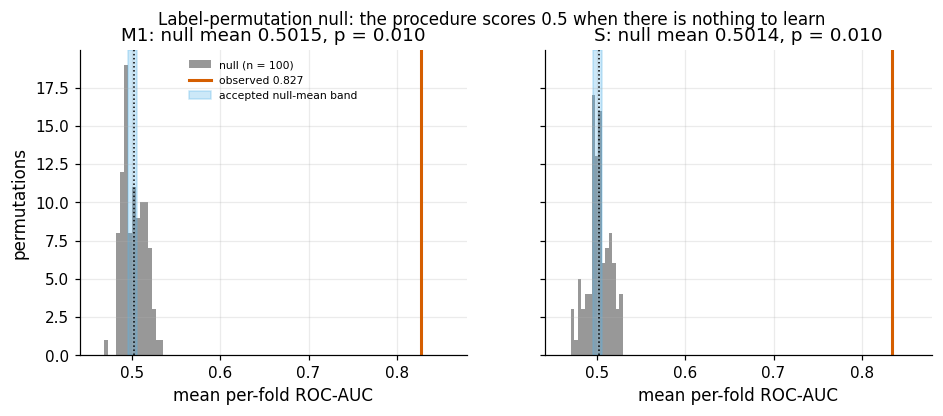

In [3]:
t0 = time.time()
PERM = {arm: RB.permutation_null(ctx, Spec(arm), n_perm=C.N_PERM, seed_=RB.seed("perm", arm), n_jobs=N_JOBS)
        for arm in RB.ADMISSIBLE_ARMS}
perm_tab = pd.DataFrame([dict(arm=a, observed=d["observed"], null_mean=d["null_mean"], null_sd=d["null_sd"],
                              null_min=d["null"].min(), null_max=d["null"].max(), p_value=d["p_value"], n_perm=d["n_perm"],
                              in_band=RB.PERM_NULL_BAND[0] <= d["null_mean"] <= RB.PERM_NULL_BAND[1])
                         for a, d in PERM.items()])
perm_tab.to_csv(OUT / "permutation.csv", index=False)
print(perm_tab.round(4).to_string(index=False))
print(f"{sum(len(ctx.folds) * (d['n_perm'] + 1) for d in PERM.values())} fits in {time.time() - t0:.0f} s")
assert perm_tab["in_band"].all(), "permutation null mean outside [0.495, 0.505]: procedural leakage suspected"

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (arm, d) in zip(axes, PERM.items()):
    ax.hist(d["null"], bins=15, color=OI["grey"], alpha=0.8, label=f"null (n = {d['n_perm']})")
    ax.axvline(d["observed"], color=OI["vermillion"], lw=2, label=f"observed {d['observed']:.3f}")
    ax.axvspan(*RB.PERM_NULL_BAND, color=OI["sky"], alpha=0.3, label="accepted null-mean band")
    ax.axvline(d["null_mean"], color="k", ls=":", lw=1)
    ax.set(title=f"{arm}: null mean {d['null_mean']:.4f}, p = {d['p_value']:.3f}", xlabel="mean per-fold ROC-AUC")
    ax.set_xlim(0.44, 0.88)
axes[0].set_ylabel("permutations")
axes[0].legend(fontsize=7, loc="upper center")
fig.suptitle("Label-permutation null: the procedure scores 0.5 when there is nothing to learn", fontsize=11)
plots.savefig(fig, "S9_permutation_null", caption="F9-1. Mean per-fold ROC-AUC of M1 and S refitted on permuted training labels "
              f"({C.N_PERM} permutations, same folds; grey) against the observed value (red). Blue band = acceptance range "
              "[0.495, 0.505] for the null mean; dotted line = null mean. Training part, Tier 1, E-ALL.")
plt.show()
S9["permutation"] = perm_tab.set_index("arm").to_dict("index")

**So what.** Both null distributions are centred on 0.5 (means printed above, inside the acceptance band) and
no permutation comes near the observed AUC (p is the smallest value attainable with this number of
permutations). The cross-validation, the in-fold preprocessing and the survey and class weights do not leak
label information into the score. This is a statement about the *procedure* only.

### 2.2 Pure-noise feature
**Why.** A feature that is pure noise must look like noise to the model: an N(0, 1) column appended to the raw
frame should get a coefficient whose bootstrap interval covers 0, should not change the AUC, and should never
be chosen by the depth-3 tree. A model that "finds" signal in noise overfits; a pipeline that turns noise into
signal leaks.

In [4]:
rng = np.random.default_rng(RB.seed("noise"))
ctx.extras["noise_n01"] = rng.standard_normal(ctx.n)
noise_rows, NOISE_CB = [], {}
for arm in RB.ADMISSIBLE_ARMS:
    sp = Spec(arm, extra=("noise_n01",))
    X_, y_, sw_, _ = RB.spec_inputs(ctx, sp)
    cb = ek.coef_bootstrap(lambda sp=sp: RB.make_pipe(sp, ctx.C0), X_, y_.astype(int), n_boot=C.N_BOOT_COEF,
                           seed=RB.seed("noise-coef", arm), fit_params=None if sw_ is None else {"model__sample_weight": sw_},
                           n_jobs=N_JOBS)
    NOISE_CB[arm] = cb
    s = cb.summary.loc["noise_n01"]
    sdz = float(RB.make_pipe(sp, ctx.C0)[:-1].fit_transform(X_)["noise_n01"].std())   # per-SD scale of the design column
    cmp_ = pair(sp, Spec(arm), tag=f"noise-{arm}")
    tr_ = RB.tree_features_used(ctx, Spec(arm, model="tree", extra=("noise_n01",)), ctx.folds, "noise_n01")
    tr4 = RB.tree_features_used(ctx, Spec(arm, model="tree", depth=4, extra=("noise_n01",)), ctx.folds, "noise_n01")
    zt = (cb.summary["coef"] / cb.summary["sd"]).abs()                                # bootstrap |z| for a scale-free rank
    rank = int(zt.rank(ascending=False)["noise_n01"])
    noise_rows.append(dict(arm=arm, coef_per_sd=s["coef"] * sdz, q_low=s["q_low"] * sdz, q_high=s["q_high"] * sdz,
                           ci_covers_0=bool(s["q_low"] <= 0 <= s["q_high"]), abs_z_rank=f"{rank}/{len(cb.summary)}", abs_z=float(zt["noise_n01"]),
                           dAUC_eall=cmp_[0]["est"], dAUC_eall_lo=cmp_[0]["lo"], dAUC_eall_hi=cmp_[0]["hi"],
                           dAUC_eall_verdict=RB.equivalence_verdict(cmp_[0]["lo"], cmp_[0]["hi"]),
                           tree3_uses=int(tr_["uses_feature"].sum()), tree4_uses=int(tr4["uses_feature"].sum()),
                           n_trees=len(tr_)))
noise_tab = pd.DataFrame(noise_rows)
noise_tab.to_csv(OUT / "noise_feature.csv", index=False)
print(noise_tab.round(4).to_string(index=False))
assert noise_tab["ci_covers_0"].all() and (noise_tab["tree3_uses"] == 0).all()
S9["noise_feature"] = noise_tab.set_index("arm").to_dict("index")

arm  coef_per_sd   q_low  q_high  ci_covers_0 abs_z_rank  abs_z  dAUC_eall  dAUC_eall_lo  dAUC_eall_hi dAUC_eall_verdict  tree3_uses  tree4_uses  n_trees
 M1       0.0118 -0.0753  0.1100         True      43/47 0.2574    -0.0000       -0.0009        0.0009         supported           0           0       26
  S       0.0482 -0.0668  0.1691         True      30/43 0.7934    -0.0001       -0.0008        0.0005         supported           0           4       26


**So what.** In both admissible arms the noise coefficient ranks near the bottom by |coefficient / bootstrap SD|,
its bootstrap interval covers 0, adding the column leaves the AUC unchanged within ±0.01, and none of the
depth-3 trees (one per training fold plus the full fit) splits on it. The depth-4 count is reported for
completeness: a deeper tree has more chances to chase noise, and that is one reason the protocol caps the
tree at depth 3.

### 2.3 Positive control
**Why.** Negative controls show the procedure is not too optimistic; a positive control shows it is not blind.
A synthetic column z = d·y + N(0, 1), with d = √2·Φ⁻¹(0.60), has a known population AUC of 0.60 – a weak but
real signal, independent of every other feature given the label. The procedure must (i) recover its AUC and
(ii) detect the increment when z is added to M1 and S (paired ΔAUC interval excluding 0).

In [5]:
ctx.extras["pos_control"] = RB.signal_feature(ctx.y, RB.POS_CONTROL_AUC, seed_=RB.seed("positive-control"))
z_auc = RB.auc_ci(ctx.y, ctx.extras["pos_control"].to_numpy(), seed_=RB.seed("z-auc"))
print(f"single-feature AUC of z: {z_auc[0]:.3f} [{z_auc[1]:.3f}, {z_auc[2]:.3f}] (design value {RB.POS_CONTROL_AUC:.2f})")
pos_rows = []
for arm in RB.ADMISSIBLE_ARMS:
    for r in pair(Spec(arm, extra=("pos_control",)), Spec(arm), tag=f"pos-{arm}"):
        pos_rows.append(dict(arm=arm, pop=r["pop"], auc_without=r["auc_b"], auc_with=r["auc_a"], est=r["est"], lo=r["lo"],
                             hi=r["hi"], interval=r["interval"], detected=bool(r["lo"] > 0)))
pos_tab = pd.DataFrame(pos_rows)
pos_tab.to_csv(OUT / "positive_control.csv", index=False)
print(pos_tab.round(4).to_string(index=False))
assert z_auc[1] <= RB.POS_CONTROL_AUC <= z_auc[2], "positive-control AUC not recovered"
assert pos_tab.loc[pos_tab["pop"] == "E-ALL", "detected"].all(), "positive control not detected on E-ALL"
S9["positive_control"] = dict(z_auc=z_auc, rows=pos_tab.to_dict("records"))

single-feature AUC of z: 0.588 [0.567, 0.610] (design value 0.60)


arm      pop  auc_without  auc_with    est     lo     hi  interval  detected
 M1    E-ALL       0.8285    0.8345 0.0061 0.0023 0.0101 bootstrap      True
 M1 E-SCREEN       0.7723    0.7844 0.0122 0.0019 0.0228 bootstrap      True
  S    E-ALL       0.8359    0.8420 0.0061 0.0021 0.0102 bootstrap      True
  S E-SCREEN       0.7807    0.7939 0.0132 0.0026 0.0242 bootstrap      True


**So what.** The column's AUC is recovered (its interval contains the design value 0.60), and adding it raises
the E-ALL AUC of both arms with an interval that excludes 0, so a signal of this size would not be missed. The
increment is much smaller than 0.10 because the remaining features already rank most cases correctly – which
also calibrates expectations: a new risk factor with a univariate AUC of 0.60 buys only a few thousandths of
AUC on top of age, adiposity and blood pressure.

## 3 Seed stability
**Why.** A verdict that flips when only the random fold assignment changes is a property of one lucky split,
not of the data. Ten seeds derived from `SEED_MASTER` (`evalkit.derive_seed`) generate ten new repeated
stratified fold sets and bootstrap streams; the hold-out, the data, C0 and the final configuration stay fixed.
Acceptance: the H2b(a) verdict of S − M1 on E-ALL is the same under all ten seeds.

10 seeds x 2 arms x 25 folds in 33 s
 seed_index      pop  auc_a  auc_b    est      lo     hi    interval          h2b
          0    E-ALL 0.8355 0.8287 0.0069 -0.0018 0.0155 corrected_t inconclusive
          0 E-SCREEN 0.7805 0.7739 0.0066 -0.0084 0.0222   bootstrap inconclusive
          1    E-ALL 0.8354 0.8290 0.0060 -0.0013 0.0133 corrected_t inconclusive
          1 E-SCREEN 0.7814 0.7735 0.0080 -0.0082 0.0224   bootstrap inconclusive
          2    E-ALL 0.8364 0.8297 0.0068  0.0005 0.0131 corrected_t inconclusive
          2 E-SCREEN 0.7834 0.7749 0.0086 -0.0072 0.0230   bootstrap inconclusive
          3    E-ALL 0.8352 0.8284 0.0071  0.0002 0.0140 corrected_t inconclusive
          3 E-SCREEN 0.7818 0.7746 0.0072 -0.0079 0.0223   bootstrap inconclusive
          4    E-ALL 0.8347 0.8271 0.0078  0.0014 0.0143 corrected_t inconclusive
          4 E-SCREEN 0.7816 0.7712 0.0104 -0.0054 0.0248   bootstrap inconclusive
          5    E-ALL 0.8356 0.8289 0.0065 -0.0014 0.0143 corr

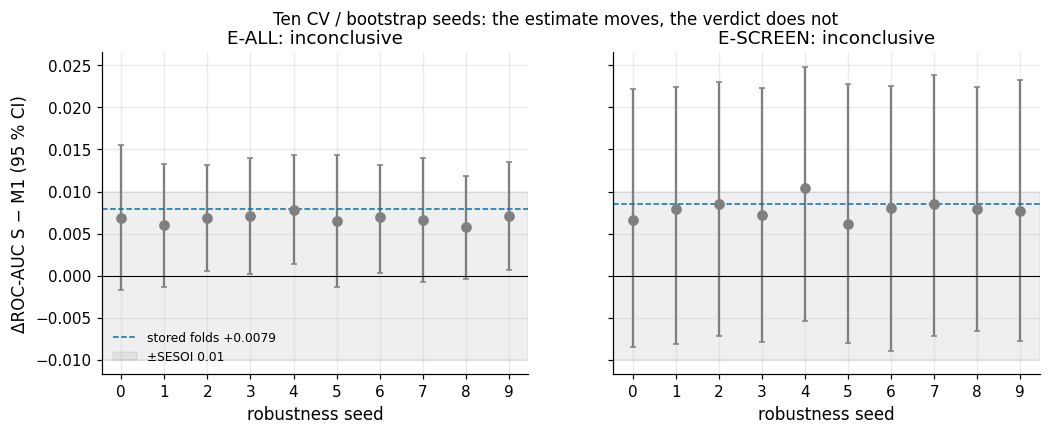

In [6]:
def prefetch(items):
    """Run many (spec, folds) pairs in one parallel batch (fills the cache used by `pair`)."""
    t0 = time.time()
    RB.run_jobs(ctx, items, n_jobs=N_JOBS, cache=RUNS)
    return time.time() - t0

SEED_FOLDS = {k: RB.seed_folds(ctx.strat, RB.seed("cv-seed", k)) for k in range(C.N_ROBUSTNESS_SEEDS)}
secs = prefetch({f"{a}{k}": (Spec(a), f) for k, f in SEED_FOLDS.items() for a in RB.ADMISSIBLE_ARMS})
seed_rows = []
for k, f in SEED_FOLDS.items():
    for r in pair(Spec("S"), Spec("M1"), f, tag=f"seed{k}"):
        seed_rows.append(dict(seed_index=k, seed=f.seed, folds_hash=f.hash[:12], **{c: r[c] for c in
                              ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b", "sesoi_class")}))
seeds = pd.DataFrame(seed_rows)
seeds.to_csv(OUT / "seed_stability.csv", index=False)
print(f"{len(SEED_FOLDS)} seeds x 2 arms x {len(ctx.folds)} folds in {secs:.0f} s")
print(seeds[["seed_index", "pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b"]].round(4).to_string(index=False))
seed_sum = seeds.groupby("pop").agg(est_min=("est", "min"), est_max=("est", "max"), est_sd=("est", "std"),
                                    lo_min=("lo", "min"), hi_max=("hi", "max"),
                                    verdicts=("h2b", lambda v: ", ".join(f"{k} x{n}" for k, n in v.value_counts().items())))
print(seed_sum.round(4).to_string())
seed_stable = seeds.loc[seeds["pop"] == "E-ALL", "h2b"].nunique() == 1
ref_v = S9["reference"]["E-ALL"]["h2b"]
print(f"E-ALL verdict identical under all seeds: {seed_stable} (reference: {ref_v})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
VCOL = {"supported": OI["green"], "refuted": OI["vermillion"], "inconclusive": OI["grey"]}
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    s = seeds[seeds["pop"] == pop].reset_index(drop=True)
    for i, r in s.iterrows():
        ax.errorbar(i, r["est"], yerr=[[r["est"] - r["lo"]], [r["hi"] - r["est"]]], fmt="o", color=VCOL[r["h2b"]], capsize=2)
    rr = S9["reference"][pop]
    ax.axhline(rr["est"], color=OI["blue"], ls="--", lw=1, label=f"stored folds {rr['est']:+.4f}")
    ax.axhspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12, label="±SESOI 0.01")
    ax.axhline(0, color="k", lw=0.7)
    ax.set(xticks=range(len(s)), xlabel="robustness seed", title=f"{pop}: {', '.join(s['h2b'].value_counts().index)}")
axes[0].set_ylabel("ΔROC-AUC S − M1 (95 % CI)")
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Ten CV / bootstrap seeds: the estimate moves, the verdict does not", fontsize=11)
plots.savefig(fig, "S9_seed_stability", caption="F9-3. ΔROC-AUC (S − M1, Tier 1) with its conservative 95 % CI under ten robustness seeds "
              "(new repeated stratified folds and bootstrap streams; data, hold-out and C0 fixed). Colour = verdict under the locked "
              "equivalence rule (grey = inconclusive); dashed = stored folds of the run mode.")
plt.show()
S9["seeds"] = dict(n=C.N_ROBUSTNESS_SEEDS, stable_eall=bool(seed_stable), summary=seed_sum.to_dict("index"))

**So what.** Across the ten seeds the point estimate of S − M1 moves only in the third decimal (min, max and SD
printed) and every interval keeps straddling +0.01, so the E-ALL verdict is the same in all ten runs. The verdict
is a property of the data, not of the split; and it stays *inconclusive* for a structural reason – the true
difference sits close to the SESOI itself, so no reasonable amount of resampling will put the interval on one
side of it.

## 4 Sensitivity table
**Why.** Many analysis choices were made once (label, weighting, imputation, tier, C, model, excluded race).
Each of the 16 pre-specified variations below changes **one** choice for **both** arms and recomputes
ΔAUC(S − M1) on E-ALL and E-SCREEN with the same engine:

* labels SL1 (HbA1c only), SL2 (self-report only), SL3 (borderline positive), SL4 (treatment-aware) and SL5
  (NCHS definition incl. fasting glucose, fasting subsample only); training *and* E-ALL evaluation use the label,
  E-SCREEN keeps the screening definition;
* survey weights in the fit: unweighted for both arms, weighted for both arms (the reference weights S only);
* imputation: `IterativeImputer` instead of the median, and complete cases (rows without any missing Tier-1 input);
* Tier 2 (lipids); C ∈ {0.01, 1, 10} besides C0 = 0.1; depth-4 tree instead of logistic regression; race added
  as a feature (excluded by design in S1); M1 with its **own** tuned C (C0 was tuned on S, which favours S).

In [7]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline

# row subsets and extra columns used by the specifications
pre = Pipeline([s for s in P.preprocessor_steps(P.ARMS["S"], 1) if s[0] in ("p01", "p02", "p03", "no_care", "p04")])
pre_frame = pre.fit(ctx.X[1]).transform(ctx.X[1])          # stateless steps only: nothing is learned from y
ctx.subsets["complete"] = pre_frame.notna().all(axis=1).to_numpy()
ctx.subsets["fasting"] = ctx.labels["SL5"].notna().to_numpy()
ctx.extras["race_feature"] = ctx.cl["race"].astype(str).astype(object).to_numpy()
print(f"complete cases (no missing Tier-1 input after aggregation): {ctx.subsets['complete'].sum():,} of {ctx.n:,}; "
      f"fasting subsample: {ctx.subsets['fasting'].sum():,} rows, {int(ctx.labels['SL5'].sum())} SL5 positives")

def tune_C(arm):
    """LogisticRegressionCV over the C grid on the arm's own design (the S7 C0 procedure, applied to the arm)."""
    sp = Spec(arm)
    X_, y_, sw_, _ = RB.spec_inputs(ctx, sp)
    design = RB.make_pipe(sp, ctx.C0)[:-1].fit_transform(X_)
    inner = StratifiedKFold(5, shuffle=True, random_state=RB.seed("ownC", arm))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        lrcv = LogisticRegressionCV(Cs=list(RB.C_GRID), cv=inner, scoring="roc_auc", max_iter=C.LR_MAX_ITER,
                                    class_weight=P.model_kwargs(P.ARMS[arm])["class_weight"], l1_ratios=(0.0,),
                                    use_legacy_attributes=False, n_jobs=N_JOBS)
        lrcv.fit(design, y_.astype(int), sample_weight=sw_)
    sc = np.asarray(lrcv.scores_).reshape(5, -1).mean(axis=0).ravel()[:len(RB.C_GRID)]
    return float(np.ravel(lrcv.C_)[0]), {str(c): round(float(v), 4) for c, v in zip(RB.C_GRID, sc)}

OWN_C = {arm: tune_C(arm) for arm in ("M0", "M1")}
for arm, (c_, sc) in OWN_C.items():
    print(f"{arm}: own C = {c_}  (inner-CV AUC by C {sc}; C0 = {ctx.C0} was tuned on S)")

SENS = [  # (name, group, spec S, spec M1, E-ALL label)
    ("SL1 HbA1c only", "label", Spec("S", label="SL1"), Spec("M1", label="SL1"), "SL1"),
    ("SL2 self-report only", "label", Spec("S", label="SL2"), Spec("M1", label="SL2"), "SL2"),
    ("SL3 borderline positive", "label", Spec("S", label="SL3"), Spec("M1", label="SL3"), "SL3"),
    ("SL4 treatment-aware", "label", Spec("S", label="SL4"), Spec("M1", label="SL4"), "SL4"),
    ("SL5 NCHS incl. FPG (fasting)", "label", Spec("S", label="SL5", rows="fasting"), Spec("M1", label="SL5", rows="fasting"), "SL5"),
    ("unweighted fit (both)", "weights", Spec("S", weighted=False), Spec("M1"), "L_comb"),
    ("survey-weighted fit (both)", "weights", Spec("S"), Spec("M1", weighted=True), "L_comb"),
    ("IterativeImputer", "imputation", Spec("S", impute="iterative"), Spec("M1", impute="iterative"), "L_comb"),
    ("complete cases", "imputation", Spec("S", rows="complete"), Spec("M1", rows="complete"), "L_comb"),
    ("Tier 2 (+ lipids)", "tier", Spec("S", tier=2), Spec("M1", tier=2), "L_comb"),
    ("C = 0.01", "C", Spec("S", C=0.01), Spec("M1", C=0.01), "L_comb"),
    ("C = 1", "C", Spec("S", C=1.0), Spec("M1", C=1.0), "L_comb"),
    ("C = 10", "C", Spec("S", C=10.0), Spec("M1", C=10.0), "L_comb"),
    ("depth-4 tree", "model", Spec("S", model="tree", depth=4), Spec("M1", model="tree", depth=4), "L_comb"),
    ("race as a feature", "features", Spec("S", extra=("race_feature",)), Spec("M1", extra=("race_feature",)), "L_comb"),
    ("M1 with its own tuned C", "C", Spec("S"), Spec("M1", C=OWN_C["M1"][0]), "L_comb"),
]
assert len(SENS) <= 16
own_gate = [Spec("M1", C=OWN_C["M1"][0]), Spec("M0", C=OWN_C["M0"][0]), Spec("M0")]
secs = prefetch({f"{i}{j}": (sp, ctx.folds) for i, row in enumerate(SENS) for j, sp in enumerate(row[2:4])}
                | {f"g{j}": (sp, ctx.folds) for j, sp in enumerate(own_gate)})
sens_rows = [dict(spec="reference (S7)", group="reference", **r) for r in ref]
for name, grp, sa, sb, lab in SENS:
    for r in pair(sa, sb, tag=f"sens-{name}", label=lab):
        sens_rows.append(dict(spec=name, group=grp, **r))
sens = pd.DataFrame(sens_rows)
sens["same_verdict_as_reference"] = [v == S9["reference"][p]["h2b"] for v, p in zip(sens["h2b"], sens["pop"])]
sens.to_csv(OUT / "sensitivity_table.csv", index=False)
print(f"{len(SENS)} specifications, {secs:.0f} s")
print(sens[["spec", "pop", "n_eval", "n_pos", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b"]].round(4).to_string(index=False))

gate_own = pair(Spec("M1", C=OWN_C["M1"][0]), Spec("M0", C=OWN_C["M0"][0]), tag="gate-ownC")
gate_c0 = pair(Spec("M1"), Spec("M0"), tag="gate-C0")
for g, nm in ((gate_c0, "C0 for both"), (gate_own, "own C each")):
    print(f"leak gate M1 - M0 ({nm}): " + "; ".join(f"{r['pop']} {r['est']:+.3f} [{r['lo']:+.3f}, {r['hi']:+.3f}]" for r in g))

eall = sens[sens["pop"] == "E-ALL"]
n_same = int(eall["same_verdict_as_reference"].sum())
print(f"E-ALL: {n_same} of {len(eall)} rows share the reference verdict ({ref_v}); "
      f"differing: {eall.loc[~eall['same_verdict_as_reference'], 'spec'].tolist()}")
esc_ = sens[sens["pop"] == "E-SCREEN"]
print(f"E-SCREEN verdicts: {esc_['h2b'].value_counts().to_dict()}; estimates {esc_['est'].min():+.3f} to {esc_['est'].max():+.3f}")
print(f"sign: E-ALL estimates {eall['est'].min():+.4f} to {eall['est'].max():+.4f}; "
      f"rows with CI wholly below 0: {int((sens['hi'] < 0).sum())}")

complete cases (no missing Tier-1 input after aggregation): 3,621 of 4,584; fasting subsample: 2,338 rows, 454 SL5 positives


M0: own C = 0.1  (inner-CV AUC by C {'0.01': 0.9536, '0.1': 0.9575, '1.0': 0.9561, '10.0': 0.9552}; C0 = 0.1 was tuned on S)
M1: own C = 0.1  (inner-CV AUC by C {'0.01': 0.8263, '0.1': 0.828, '1.0': 0.8273, '10.0': 0.8272}; C0 = 0.1 was tuned on S)


16 specifications, 53 s
                        spec      pop  n_eval  n_pos  auc_a  auc_b     est      lo     hi    interval          h2b
              reference (S7)    E-ALL    4584    777 0.8359 0.8285  0.0079  0.0000 0.0158 corrected_t inconclusive
              reference (S7) E-SCREEN    3934    127 0.7807 0.7723  0.0085 -0.0081 0.0236   bootstrap inconclusive
              SL1 HbA1c only    E-ALL    4584    582 0.8316 0.8206  0.0116  0.0002 0.0230 corrected_t inconclusive
              SL1 HbA1c only E-SCREEN    3934    127 0.7845 0.7796  0.0049 -0.0124 0.0214   bootstrap inconclusive
        SL2 self-report only    E-ALL    4584    650 0.8389 0.8329  0.0062 -0.0035 0.0160 corrected_t inconclusive
        SL2 self-report only E-SCREEN    3934    127 0.7668 0.7587  0.0081 -0.0087 0.0245   bootstrap inconclusive
     SL3 borderline positive    E-ALL    4584    920 0.8254 0.8193  0.0061  0.0001 0.0121 corrected_t inconclusive
     SL3 borderline positive E-SCREEN    3934    127 0.7

leak gate M1 - M0 (C0 for both): E-ALL -0.131 [-0.148, -0.114]; E-SCREEN -0.072 [-0.109, -0.032]
leak gate M1 - M0 (own C each): E-ALL -0.131 [-0.148, -0.114]; E-SCREEN -0.072 [-0.113, -0.030]
E-ALL: 17 of 17 rows share the reference verdict (inconclusive); differing: []
E-SCREEN verdicts: {'inconclusive': 17}; estimates -0.012 to +0.020
sign: E-ALL estimates -0.0061 to +0.0116; rows with CI wholly below 0: 0


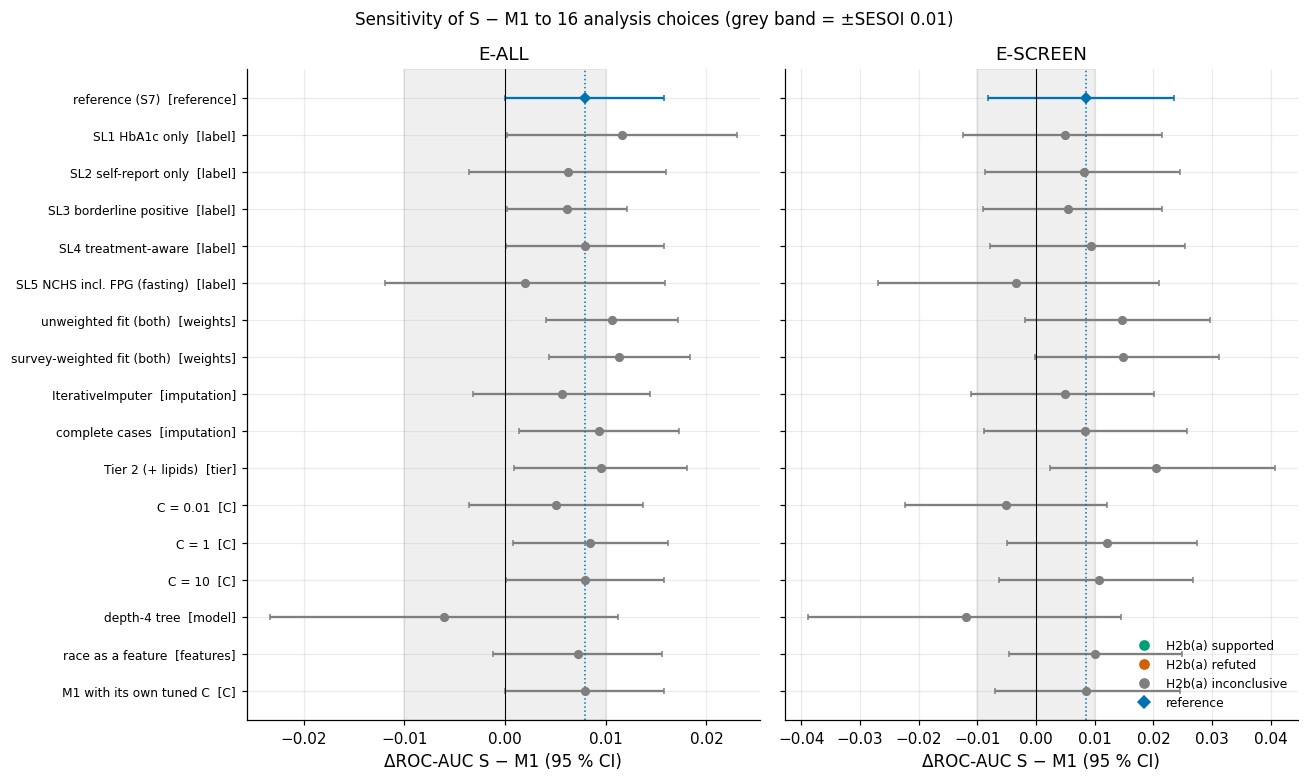

In [8]:
from matplotlib.lines import Line2D
fig, axes = plt.subplots(1, 2, figsize=(12, 7.2), sharey=True)
order = list(dict.fromkeys(sens["spec"]))
groups_ = sens.drop_duplicates("spec").set_index("spec")["group"]
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    s = sens[sens["pop"] == pop].set_index("spec").loc[order]
    for i, (nm, r) in enumerate(s.iterrows()):
        ax.errorbar(r["est"], i, xerr=[[r["est"] - r["lo"]], [r["hi"] - r["est"]]], fmt="D" if i == 0 else "o",
                    color=OI["blue"] if i == 0 else VCOL[r["h2b"]], capsize=2, ms=5)
    ax.axvspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12)
    ax.axvline(0, color="k", lw=0.7)
    ax.axvline(s["est"].iloc[0], color=OI["blue"], ls=":", lw=1)
    ax.set(title=pop, xlabel="ΔROC-AUC S − M1 (95 % CI)")
axes[0].set_yticks(range(len(order)), [f"{o}  [{groups_[o]}]" for o in order], fontsize=8)
axes[0].invert_yaxis()
axes[1].legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=f"H2b(a) {v}") for v, c in VCOL.items()]
               + [Line2D([], [], marker="D", ls="", color=OI["blue"], label="reference")], fontsize=8, loc="lower right")
fig.suptitle("Sensitivity of S − M1 to 16 analysis choices (grey band = ±SESOI 0.01)", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S9_sensitivity_forest", caption="F9-2. ΔROC-AUC (S − M1) with conservative 95 % CIs for the reference and 16 one-at-a-time "
              "variations (labels SL1-SL5, fit weights, imputation, tier, C, depth-4 tree, race as a feature, M1 with its own tuned C); "
              "left E-ALL (scored against the row's label), right E-SCREEN. Colour = H2b(a) verdict under the locked equivalence rule.")
plt.show()
S9["sensitivity"] = dict(n_specs=len(SENS), eall_same_verdict=n_same, eall_rows=len(eall),
                         own_C={a: c for a, (c, _) in OWN_C.items()},
                         leak_gate_C0={r["pop"]: {k: r[k] for k in ("est", "lo", "hi")} for r in gate_c0},
                         leak_gate_own_C={r["pop"]: {k: r[k] for k in ("est", "lo", "hi")} for r in gate_own},
                         table=sens[["spec", "group", "pop", "n_eval", "n_pos", "auc_a", "auc_b", "est", "lo", "hi", "interval",
                                     "mdd", "h2b"]].round(5).to_dict("records"))

**So what.** Reading the forest plot (numbers in the tables above):

* **The E-ALL verdict does not move.** Every one of the 16 variations gives the same H2b(a) verdict as the reference
  (count printed above): the interval of S − M1 never lies inside ±0.01, and never wholly above +0.01. No variation
  produces an interval wholly below 0, i.e. S is never decisively *worse* than M1.
* **Labels and weighting move the estimate most.** Weighting *both* arms the same way (unweighted or survey-weighted)
  enlarges the S advantage to about +0.01 with an interval excluding 0 – part of the reference gap is S's own survey
  weighting costing it unweighted AUC (B6b). The label changes the size of the gap (HbA1c-only largest, NCHS SL5 on the
  fasting half smallest and widest), not its direction on E-ALL.
* **The depth-4 tree is the only model-class change, and it reverses the sign** (with a wide interval): for a tree the
  systematic steps (scaling, splines, one-hot rules) are irrelevant (B5-e), so S − M1 there only measures noise in two
  unstable trees – one more reason the tree is a probe, not the model.
* **The C0 bias is nil here.** Tuned on their own, M0 and M1 pick the same C as S (printed), so "M1 with its own C"
  reproduces the reference and the leak gate M1 − M0 is unchanged: the HR2 rule "same model for every arm" did not
  favour S or manufacture the leakage drop.
* **E-SCREEN**: all intervals are wide (about 25 positives per fold) and every verdict is inconclusive; point estimates
  range around zero, the screening value of the extra preparation is not established either way.

## 5 Specification curve
**Why.** The sensitivity table changes one choice at a time; a specification curve (Simonsohn et al. 2020)
crosses the choices that the table showed to matter most, so that interactions between them cannot hide a
different answer. Grid: 5 training labels (L_comb, SL1–SL4) × 3 weighting schemes (as specified: S weighted and M1
unweighted; both unweighted; both weighted) × 4 values of C = **60 specifications**, each with ΔAUC(S − M1) and its
conservative CI on E-ALL and E-SCREEN. This extends, and does not replace, the core table.

In [9]:
import itertools
LABELS_SC = {"L_comb": "arm", "SL1": "SL1", "SL2": "SL2", "SL3": "SL3", "SL4": "SL4"}
WEIGHTING = ("as specified", "both unweighted", "both weighted")
grid = []
for (lab, lab_spec), wt, c in itertools.product(LABELS_SC.items(), WEIGHTING, RB.C_GRID):
    cc = None if c == ctx.C0 else c
    sa = Spec("S", label=lab_spec, C=cc, weighted=False if wt == "both unweighted" else None)
    sb = Spec("M1", label=lab_spec, C=cc, weighted=True if wt == "both weighted" else None)
    grid.append(dict(label=lab, weighting=wt, C=c, sa=sa, sb=sb))
assert len(grid) == 60
secs = prefetch({f"sc{i}{j}": (g[k], ctx.folds) for i, g in enumerate(grid) for j, k in enumerate(("sa", "sb"))})
sc_rows = []
for i, g in enumerate(grid):
    for r in pair(g["sa"], g["sb"], tag=f"curve{i}", label=g["label"]):
        sc_rows.append(dict(spec_id=i, label=g["label"], weighting=g["weighting"], C=g["C"], **{k: r[k] for k in
                            ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b", "sesoi_class")}))
curve = pd.DataFrame(sc_rows)
curve.to_csv(OUT / "specification_curve.csv", index=False)
print(f"60 specifications x 2 arms in {secs:.0f} s")
cs = curve.groupby("pop").agg(n=("est", "size"), est_median=("est", "median"), est_min=("est", "min"), est_max=("est", "max"),
                              share_positive=("est", lambda v: (v > 0).mean()),
                              share_ci_above_0=("lo", lambda v: (v > 0).mean()),
                              share_ci_below_0=("hi", lambda v: (v < 0).mean()),
                              share_beyond_sesoi=("lo", lambda v: (v >= C.SESOI["roc_auc"]).mean()))
print(cs.round(3).to_string())
print(curve.groupby(["pop", "h2b"]).size().unstack(fill_value=0).to_string())
print("median E-ALL estimate by factor:")
for fac in ("label", "weighting", "C"):
    print("  ", curve[curve["pop"] == "E-ALL"].groupby(fac)["est"].median().round(4).to_dict())

60 specifications x 2 arms in 91 s
           n  est_median  est_min  est_max  share_positive  share_ci_above_0  share_ci_below_0  share_beyond_sesoi
pop                                                                                                               
E-ALL     60       0.010    0.005    0.018            1.00              0.85               0.0                 0.0
E-SCREEN  60       0.012   -0.011    0.021            0.75              0.30               0.0                 0.0
h2b       inconclusive
pop                   
E-ALL               60
E-SCREEN            60
median E-ALL estimate by factor:
   {'L_comb': 0.0098, 'SL1': 0.0146, 'SL2': 0.01, 'SL3': 0.0079, 'SL4': 0.0104}
   {'as specified': 0.0074, 'both unweighted': 0.0105, 'both weighted': 0.0113}
   {0.01: 0.009, 0.1: 0.0103, 1.0: 0.0109, 10.0: 0.0108}


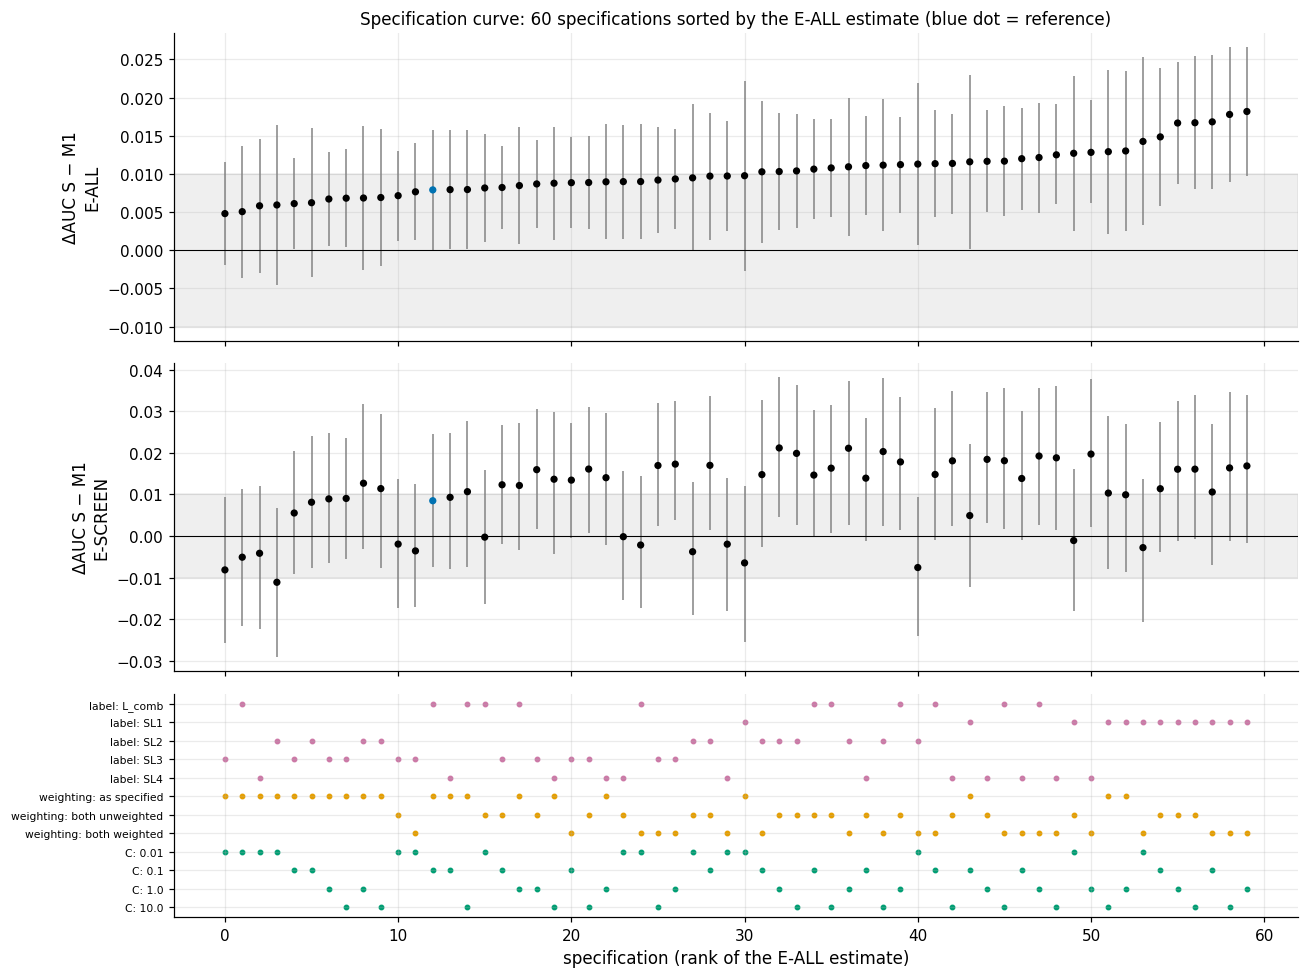

In [10]:
e_all = curve[curve["pop"] == "E-ALL"].sort_values("est").reset_index(drop=True)
order_ids = e_all["spec_id"].tolist()
e_scr = curve[curve["pop"] == "E-SCREEN"].set_index("spec_id").loc[order_ids].reset_index()
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, gridspec_kw={"height_ratios": [2.2, 2.2, 1.6]})
for ax, d, pop in ((axes[0], e_all, "E-ALL"), (axes[1], e_scr, "E-SCREEN")):
    x = np.arange(len(d))
    ax.vlines(x, d["lo"], d["hi"], color=[VCOL[v] for v in d["h2b"]], lw=1.2, alpha=0.8)
    ax.scatter(x, d["est"], s=14, color=[OI["blue"] if (l == "L_comb" and w == "as specified" and c == ctx.C0) else "k"
                                          for l, w, c in zip(d["label"], d["weighting"], d["C"])], zorder=3)
    ax.axhspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12)
    ax.axhline(0, color="k", lw=0.7)
    ax.set_ylabel(f"ΔAUC S − M1\n{pop}")
axes[0].set_title("Specification curve: 60 specifications sorted by the E-ALL estimate (blue dot = reference)", fontsize=11)
ax = axes[2]
rows_ind = [("label", l) for l in LABELS_SC] + [("weighting", w) for w in WEIGHTING] + [("C", c) for c in RB.C_GRID]
for j, (fac, val) in enumerate(rows_ind):
    hit = (e_all[fac] == val).to_numpy()
    ax.scatter(np.flatnonzero(hit), np.full(hit.sum(), j), s=8, color=OI["purple"] if fac == "label" else OI["orange"] if fac == "weighting" else OI["green"])
ax.set_yticks(range(len(rows_ind)), [f"{fac}: {val}" for fac, val in rows_ind], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("specification (rank of the E-ALL estimate)")
fig.tight_layout()
plots.savefig(fig, "S9_specification_curve", caption="Specification curve (extension). 60 specifications = 5 training labels x 3 weighting "
              "schemes x 4 values of C. Top: ΔROC-AUC (S − M1) on E-ALL with conservative 95 % CI, sorted; middle: E-SCREEN in the same "
              "order; bottom: which choices define each specification. Line colour = H2b(a) verdict (grey inconclusive, green "
              "equivalent, red refuted); grey band = ±SESOI 0.01.")
plt.show()
S9["specification_curve"] = dict(n=60, summary=cs.round(5).to_dict("index"),
                                 verdicts=curve.groupby(["pop", "h2b"]).size().unstack(fill_value=0).to_dict("index"))

**So what.** All 60 combinations put S *ahead* of M1 on E-ALL, and in most of them the interval excludes 0
(shares printed) – the direction is robust. But no combination clears the SESOI with confidence, and none puts the
interval inside ±0.01, so every one of the 60 verdicts is the reference verdict, *inconclusive*. The factor medians
show what drives the size of the gap: the reference ("as specified": S survey-weighted, M1 not) sits at the low end,
because S's own survey weighting costs it some unweighted AUC (B6b); weighting both arms alike moves the median to
about the SESOI itself, and the HbA1c-only label (SL1) gives the largest gaps. On E-SCREEN the curve scatters around
small positive values with wide intervals. The H2b(a) verdict is not the product of one forking path; it is what the
whole garden of forking paths says – a small, consistent advantage of S whose size cannot be pinned against 0.01.

## 6 Survey-cluster cross-validation
**Why.** NHANES samples counties (PSUs) within strata; people in the same PSU share geography, examination
logistics and season. Ordinary folds put neighbours on both sides of a split, which can flatter the AUC of features
that encode place. `StratifiedGroupKFold` with groups = stratum × PSU keeps each survey cluster inside one fold
(repeated with derived seeds), so the test fold always contains clusters the model has never seen.

In [11]:
groups = (ctx.cl[C.STRATA].astype(int) * 10 + ctx.cl[C.PSU].astype(int)).to_numpy()
GFOLDS = RB.group_folds(ctx.strat, groups, RB.seed("group-cv"))
gsz = pd.DataFrame([dict(fold=i, n_test=len(te), n_clusters=len(np.unique(groups[te])), pos=int(ctx.y[te].sum()),
                         pos_escreen=int(ctx.y_esc[te][ctx.esc[te]].sum())) for i, (_, te) in enumerate(GFOLDS)])
assert all(len(set(groups[te]) & set(groups[tr])) == 0 for tr, te in GFOLDS), "a cluster appears on both sides of a split"
print(f"{len(np.unique(groups))} strata x PSU clusters in the training part; grouped folds: n_test {gsz['n_test'].min()}-{gsz['n_test'].max()}, "
      f"clusters per test fold {gsz['n_clusters'].min()}-{gsz['n_clusters'].max()}, E-SCREEN positives {gsz['pos_escreen'].min()}-{gsz['pos_escreen'].max()}")
secs = prefetch({f"g{a}": (Spec(a), GFOLDS) for a in RB.ADMISSIBLE_ARMS})
gcv = pair(Spec("S"), Spec("M1"), GFOLDS, tag="group-cv")
gcv_tab = pd.DataFrame([dict(folds="stored stratified", **{k: r[k] for k in ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b")}) for r in ref]
                       + [dict(folds="strata x PSU grouped", **{k: r[k] for k in ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b")}) for r in gcv])
gcv_tab = gcv_tab.rename(columns={"auc_a": "auc_S", "auc_b": "auc_M1"})
gcv_tab.to_csv(OUT / "grouped_cv.csv", index=False)
print(gcv_tab.round(4).to_string(index=False))
dS = {p: gcv_tab.query("folds == 'strata x PSU grouped' and pop == @p")["auc_S"].iloc[0] - gcv_tab.query("folds == 'stored stratified' and pop == @p")["auc_S"].iloc[0]
      for p in ("E-ALL", "E-SCREEN")}
print(f"AUC of S, grouped minus stratified folds: E-ALL {dS['E-ALL']:+.4f}, E-SCREEN {dS['E-SCREEN']:+.4f}")
S9["grouped_cv"] = dict(n_clusters=int(len(np.unique(groups))), table=gcv_tab.round(5).to_dict("records"),
                        auc_S_grouped_minus_stratified=dS)

30 strata x PSU clusters in the training part; grouped folds: n_test 805-1058, clusters per test fold 5-7, E-SCREEN positives 20-31


               folds      pop  auc_S  auc_M1    est      lo     hi    interval          h2b
   stored stratified    E-ALL 0.8359  0.8285 0.0079  0.0000 0.0158 corrected_t inconclusive
   stored stratified E-SCREEN 0.7807  0.7723 0.0085 -0.0081 0.0236   bootstrap inconclusive
strata x PSU grouped    E-ALL 0.8313  0.8257 0.0055 -0.0001 0.0118   bootstrap inconclusive
strata x PSU grouped E-SCREEN 0.7797  0.7727 0.0070 -0.0086 0.0221   bootstrap inconclusive
AUC of S, grouped minus stratified folds: E-ALL -0.0046, E-SCREEN -0.0010


**So what.** Holding whole survey clusters out changes the AUC of S by only a few thousandths (printed): the
admissible features do not exploit place-specific structure, so the cross-validated numbers are not inflated by
cluster sharing. The S − M1 verdict is the same under grouped folds. Grouped folds are less balanced (fold sizes and
E-SCREEN positives vary more, printed above), which is why they are a check rather than the primary design.

## 7 Missing HbA1c: inverse-probability weights and delta adjustment
**Why.** The cohort keeps only examined adults *with* an HbA1c value. §3 showed the missingness is not MCAR
(NH Black OR about 1.85; register DR-S3-04), and §5 bounded the prevalence with Manski bounds (DR-S5-08); both
deferred two sensitivity analyses to this stage:

1. **MAR given covariates – inverse-probability weighting (IPW).** The S3 missingness model is refitted on examined,
   non-pregnant adults (the population the cohort is drawn from); each cohort member gets a stabilised weight
   P(observed) / P(observed | x). Used (a) for the prevalence and (b) for ΔAUC(S − M1), weighting evaluation only or
   fit and evaluation.
2. **MNAR – delta adjustment (pattern mixture).** People without HbA1c who report diabetes are positive anyway. For
   the others, the MAR probability of HbA1c ≥ 6.5 (a logit on the S3 covariates fitted on the E-SCREEN rows of the
   training part) is shifted by δ on the log-odds scale: δ = 0 is MAR, δ = log 3 means three-fold odds among the
   unmeasured. Manski-type bounds (all undetermined negative / all positive) bracket every δ.

In [12]:
ex = RB.examined_population()
miss = ex["a1c_observed"].eq(0)
obs_fit = RB.observation_model(ex)
ci_ = obs_fit.conf_int()
or_obs = pd.DataFrame({"OR_missing": np.exp(-obs_fit.params), "ci_low": np.exp(-ci_[1]), "ci_high": np.exp(-ci_[0])}).drop("const")
s3_or = pd.read_csv(C.RESULTS_DIR / "S3" / "missingness_or.csv", index_col=0)
or_cmp = or_obs.join(s3_or[["OR"]].rename(columns={"OR": "OR_missing_S3"}))
print(f"examined non-pregnant adults {len(ex):,}; without HbA1c {int(miss.sum())} ({miss.mean():.1%}); cohort {int((~miss).sum()):,}")
print(or_cmp.round(3).to_string())
assert int((~miss).sum()) == io.COHORT_N
assert abs(or_cmp.loc["NH Black", "OR_missing"] - or_cmp.loc["NH Black", "OR_missing_S3"]) < 0.1   # same model, 37 fewer rows
p_obs = pd.Series(obs_fit.predict(), index=ex["SEQN"].to_numpy())
ipw_all = (~miss).mean() / p_obs                          # stabilised weight
coh = ctx.clean.copy()
coh["ipw"] = ipw_all.reindex(coh["SEQN"]).to_numpy()
coh["w_mec_ipw"] = coh[C.WEIGHT_MEC] * coh["ipw"]
ctx.ipw = coh["ipw"].to_numpy()[ctx.train_idx]
print(f"stabilised IPW in the cohort: min {coh['ipw'].min():.3f}, median {coh['ipw'].median():.3f}, max {coh['ipw'].max():.3f}; "
      f"Kish deff {sv.kish_deff(coh['ipw']):.3f}")

prev_rows = []
for nm, wcol in (("WTPH2YR (blood non-response adjusted)", C.WEIGHT_PHLEB), ("WTMEC2YR (complete case)", C.WEIGHT_MEC),
                 ("WTMEC2YR x IPW", "w_mec_ipw")):
    wp = sv.weighted_prop(coh, "L_comb", weight=wcol)
    prev_rows.append(dict(weighting=nm, est=wp["est"], ci_low=wp["ci_low"], ci_high=wp["ci_high"], df=wp["df"]))
prev_tab = pd.DataFrame(prev_rows)
print(prev_tab.round(4).to_string(index=False))
assert abs(prev_tab.loc[0, "est"] - 0.140) < 0.0015, "WTPH2YR prevalence must reproduce 14.0 % (process doc §8)"

ipw_cmp = pair(Spec("S"), Spec("M1"), tag="ipw-eval", w=ctx.ipw) + pair(Spec("S", ipw=True), Spec("M1", ipw=True), tag="ipw-fit", w=ctx.ipw)
ipw_tab = pd.DataFrame([dict(variant=v, **{k: r[k] for k in ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b")})
                        for v, r in zip(["IPW evaluation"] * 2 + ["IPW fit + evaluation"] * 2, ipw_cmp)])
print(ipw_tab.round(4).to_string(index=False))

examined non-pregnant adults 6,023; without HbA1c 293 (4.9%); cohort 5,730
                        OR_missing  ci_low  ci_high  OR_missing_S3
age (per 10 y)               0.892   0.825    0.965          0.893
female                       0.940   0.738    1.196          0.948
NH Black                     1.780   1.293    2.451          1.853
NH Asian                     1.374   0.840    2.249          1.383
Mexican American             0.723   0.414    1.264          0.772
Other Hispanic               0.845   0.543    1.315          0.842
Other/Multi                  1.245   0.785    1.974          1.244
PIR (per unit)               0.821   0.754    0.894          0.820
PIR missing                  1.564   1.142    2.141          1.572
BMI (per unit)               0.997   0.980    1.014          0.997
BMI missing                  2.673   1.448    4.933          2.646
uninsured                    0.717   0.449    1.146          0.699
no usual place of care       1.150   0.789    1.677   

             variant      pop  auc_a  auc_b    est      lo     hi    interval          h2b
      IPW evaluation    E-ALL 0.8359 0.8284 0.0079  0.0000 0.0158 corrected_t inconclusive
      IPW evaluation E-SCREEN 0.7801 0.7717 0.0085 -0.0080 0.0252   bootstrap inconclusive
IPW fit + evaluation    E-ALL 0.8356 0.8286 0.0072 -0.0009 0.0154 corrected_t inconclusive
IPW fit + evaluation E-SCREEN 0.7798 0.7706 0.0091 -0.0074 0.0249   bootstrap inconclusive


In [13]:
import statsmodels.api as sm
Xd_ex = RB.missingness_design(ex).drop(columns=["self-reported diabetes"])
seq_pos = pd.Series(np.arange(len(ex)), index=ex["SEQN"].to_numpy())
tr_rows = seq_pos.reindex(ctx.cl["SEQN"]).to_numpy()
fit_rows = tr_rows[ctx.esc]                                     # training-part E-SCREEN rows (hold-out untouched)
mar_fit = sm.Logit(ctx.y_esc[ctx.esc], sm.add_constant(Xd_ex.iloc[fit_rows])).fit(disp=0)
miss_idx = np.flatnonzero(miss.to_numpy())
miss_self = ex["DIQ010"].eq(1).to_numpy()[miss_idx]
p_mar = mar_fit.predict(sm.add_constant(Xd_ex, has_constant="add").iloc[miss_idx]).to_numpy()
from sklearn.metrics import roc_auc_score
print(f"MAR model for HbA1c >= 6.5 among the undiagnosed: fitted on {len(fit_rows):,} training-part E-SCREEN rows "
      f"({int(ctx.y_esc[ctx.esc].sum())} positives), in-sample AUC {roc_auc_score(ctx.y_esc[ctx.esc], mar_fit.predict()):.3f}")
print(f"missing rows: {len(miss_idx)}; self-reported diabetes {int(miss_self.sum())}; undetermined {int((~miss_self).sum())}, "
      f"mean MAR probability {p_mar[~miss_self].mean():.3f}")

DELTAS = np.array([-1.0, -0.5, 0.0, 0.5, 1.0, np.log(3), 1.5, 2.0, 3.0])
w_obs = coh[C.WEIGHT_MEC].to_numpy()
w_m = ex[C.WEIGHT_MEC].to_numpy()[miss_idx]
dprev = RB.delta_prevalence(coh["L_comb"].to_numpy(), w_obs, miss_self, p_mar, w_m, DELTAS)
print(dprev.round(4).to_string(index=False))
print(f"complete case (MEC) {dprev.attrs['complete_case']:.4f}; Manski bounds [{dprev.attrs['manski_low']:.4f}, {dprev.attrs['manski_high']:.4f}] "
      f"(S5: [{pd.read_csv(C.RESULTS_DIR / 'S5' / 'manski_bounds.csv').iloc[0]['lower']:.4f}, "
      f"{pd.read_csv(C.RESULTS_DIR / 'S5' / 'manski_bounds.csv').iloc[0]['upper']:.4f}])")
from scipy.optimize import brentq
f_tip = lambda d: RB.delta_prevalence(coh["L_comb"].to_numpy(), w_obs, miss_self, p_mar, w_m, [d])["prevalence"].iloc[0] - 0.158
tip = brentq(f_tip, 0, 20) if f_tip(20) > 0 else np.nan
print(f"delta needed to reach the DB516 prevalence of 15.8 %: {tip:.2f} (odds ratio {np.exp(tip):.1f})" if np.isfinite(tip)
      else "15.8 % is not reachable even with every undetermined person positive")

# delta-adjusted S - M1: full-training-part models score the people without HbA1c
raw_ex = io.load_merged(fix=False, sentinels="none")
raw_miss = raw_ex.set_index("SEQN").loc[ex["SEQN"].to_numpy()[miss_idx]].reset_index()
pa_m = RB.fit_full(ctx, Spec("S")).predict_proba(P.raw_feature_frame(raw_miss, 1))[:, 1]
pb_m = RB.fit_full(ctx, Spec("M1")).predict_proba(P.raw_feature_frame(raw_miss, 1))[:, 1]
ref_oof = RB.run_many(ctx, {"S": Spec("S"), "M1": Spec("M1")}, n_jobs=N_JOBS, cache=RUNS)
pa_o, pb_o = ek.mean_oof(ref_oof["S"], ctx.n), ek.mean_oof(ref_oof["M1"], ctx.n)
N_DRAW = max(50, C.N_BOOT // 5)
dauc = []
for pop, om, mm, yo in (("E-ALL", None, None, ctx.y), ("E-SCREEN", ctx.esc, ~miss_self, ctx.y_esc)):
    d = RB.delta_auc(yo, pa_o, pb_o, miss_self, p_mar, pa_m, pb_m, DELTAS, n_draw=N_DRAW, seed_=RB.seed("delta-auc", pop),
                     obs_mask=om, miss_mask=mm)
    d.insert(0, "pop", pop)
    dauc.append(d)
dauc = pd.concat(dauc, ignore_index=True)
dprev.to_csv(OUT / "mnar_delta_prevalence.csv", index=False)
dauc.to_csv(OUT / "mnar_delta_auc.csv", index=False)
pd.concat([prev_tab.assign(kind="prevalence"), ipw_tab.assign(kind="dAUC S-M1")]).to_csv(OUT / "ipw.csv", index=False)
print(dauc.round(4).to_string(index=False))
print(f"E-ALL S - M1 across all delta and Manski scenarios: {dauc.loc[dauc['pop'] == 'E-ALL', 'diff'].min():+.4f} to "
      f"{dauc.loc[dauc['pop'] == 'E-ALL', 'diff'].max():+.4f} (complete-case pooled {S9['reference']['E-ALL']['est']:+.4f})")

MAR model for HbA1c >= 6.5 among the undiagnosed: fitted on 3,934 training-part E-SCREEN rows (127 positives), in-sample AUC 0.802
missing rows: 293; self-reported diabetes 49; undetermined 244, mean MAR probability 0.036
  delta  odds_ratio  prevalence
-1.0000      0.3679      0.1399
-0.5000      0.6065      0.1402
 0.0000      1.0000      0.1406
 0.5000      1.6487      0.1413
 1.0000      2.7183      0.1422
 1.0986      3.0000      0.1425
 1.5000      4.4817      0.1436
 2.0000      7.3891      0.1454
 3.0000     20.0855      0.1506
complete case (MEC) 0.1393; Manski bounds [0.1395, 0.1811] (S5: [0.1395, 0.1811])
delta needed to reach the DB516 prevalence of 15.8 %: 4.07 (odds ratio 58.7)


     pop   delta            scenario  auc_a  auc_b    diff  diff_lo  diff_hi
   E-ALL -1.0000               delta 0.8361 0.8286  0.0075   0.0071   0.0079
   E-ALL -0.5000               delta 0.8359 0.8284  0.0075   0.0069   0.0080
   E-ALL  0.0000               delta 0.8358 0.8282  0.0076   0.0068   0.0083
   E-ALL  0.5000               delta 0.8354 0.8278  0.0076   0.0068   0.0085
   E-ALL  1.0000               delta 0.8346 0.8269  0.0077   0.0068   0.0087
   E-ALL  1.0986               delta 0.8345 0.8268  0.0078   0.0066   0.0089
   E-ALL  1.5000               delta 0.8335 0.8257  0.0078   0.0067   0.0090
   E-ALL  2.0000               delta 0.8321 0.8243  0.0078   0.0064   0.0091
   E-ALL  3.0000               delta 0.8251 0.8174  0.0077   0.0059   0.0092
   E-ALL     NaN manski_all_negative 0.8362 0.8287  0.0074      NaN      NaN
   E-ALL     NaN manski_all_positive 0.7587 0.7549  0.0038      NaN      NaN
E-SCREEN -1.0000               delta 0.7788 0.7703  0.0085   0.0060   0.0113

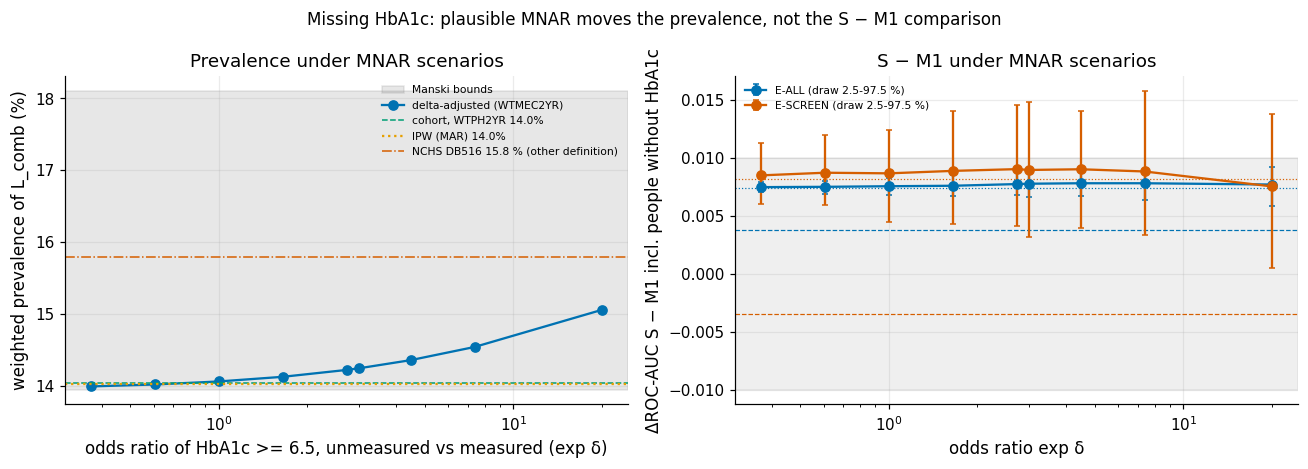

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
ax.axhspan(dprev.attrs["manski_low"] * 100, dprev.attrs["manski_high"] * 100, color=OI["grey"], alpha=0.18, label="Manski bounds")
ax.plot(dprev["odds_ratio"], dprev["prevalence"] * 100, "o-", color=OI["blue"], label="delta-adjusted (WTMEC2YR)")
ax.axhline(prev_tab.loc[0, "est"] * 100, color=OI["green"], ls="--", lw=1, label=f"cohort, WTPH2YR {prev_tab.loc[0, 'est']:.1%}")
ax.axhline(prev_tab.loc[2, "est"] * 100, color=OI["orange"], ls=":", lw=1.5, label=f"IPW (MAR) {prev_tab.loc[2, 'est']:.1%}")
ax.axhline(15.8, color=OI["vermillion"], ls="-.", lw=1, label="NCHS DB516 15.8 % (other definition)")
ax.set_xscale("log")
ax.set(xlabel="odds ratio of HbA1c >= 6.5, unmeasured vs measured (exp δ)", ylabel="weighted prevalence of L_comb (%)",
       title="Prevalence under MNAR scenarios")
ax.legend(fontsize=7)
ax = axes[1]
for pop, col in (("E-ALL", OI["blue"]), ("E-SCREEN", OI["vermillion"])):
    d = dauc[(dauc["pop"] == pop) & (dauc["scenario"] == "delta")]
    ax.errorbar(np.exp(d["delta"]), d["diff"], yerr=[d["diff"] - d["diff_lo"], d["diff_hi"] - d["diff"]],
                fmt="o-", color=col, capsize=2, label=f"{pop} (draw 2.5-97.5 %)")
    for _, r in dauc[(dauc["pop"] == pop) & (dauc["scenario"] != "delta")].iterrows():
        ax.axhline(r["diff"], color=col, lw=0.8, ls=":" if "negative" in r["scenario"] else "--")
ax.axhspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12)
ax.set_xscale("log")
ax.set(xlabel="odds ratio exp δ", ylabel="ΔROC-AUC S − M1 incl. people without HbA1c", title="S − M1 under MNAR scenarios")
ax.legend(fontsize=7)
fig.suptitle("Missing HbA1c: plausible MNAR moves the prevalence, not the S − M1 comparison", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S9_mnar_delta", caption="Left: weighted prevalence of L_comb in examined non-pregnant adults when the people without HbA1c "
              "(who did not report diabetes) have exp(δ) times the MAR odds of HbA1c >= 6.5; grey = Manski bounds; lines = WTPH2YR cohort "
              "estimate, IPW estimate and the DB516 figure (different definition, see section 8). Right: ΔROC-AUC (S − M1) when those "
              "people are added to E-ALL / E-SCREEN with labels drawn under δ (dotted / dashed = Manski all-negative / all-positive).")
plt.show()
S9["mnar"] = dict(n_examined=int(len(ex)), n_missing=int(miss.sum()), n_missing_self=int(miss_self.sum()),
                  ipw_range=[float(coh["ipw"].min()), float(coh["ipw"].max())], prevalence=prev_tab.round(5).to_dict("records"),
                  ipw_dauc=ipw_tab.round(5).to_dict("records"), delta_prevalence=dprev.round(5).to_dict("records"),
                  manski=[dprev.attrs["manski_low"], dprev.attrs["manski_high"]], tipping_delta_db516=tip,
                  delta_auc=dauc.round(5).to_dict("records"))

**So what.** Three results close the deferred register items DR-S3-04 and DR-S5-08:

* **MAR (IPW).** Re-weighting the complete cases to the examined population changes the weighted prevalence by about a
  tenth of a percentage point (table above) – the same size as the WTPH2YR non-response adjustment that S5 found, so the
  official blood weight already absorbs the covariate-driven part of the missingness. IPW moves ΔAUC(S − M1) by less than
  0.001 and leaves the verdict unchanged.
* **MNAR (delta).** Even if people without HbA1c had several times the odds of an elevated value (δ up to log 20), the
  prevalence stays well inside the Manski band, and about 4–5 % missingness is too little to lift it to the DB516 value
  unless almost every unmeasured person were diabetic (tipping point printed). The 14.0 % vs 15.8 % gap is therefore a
  *definition* gap (section 8), not a missing-data artefact.
* **Model comparison.** Adding the people without HbA1c to the evaluation set with labels drawn under any δ from
  −1 to 3 shifts ΔAUC(S − M1) by less than 0.001 on E-ALL and E-SCREEN. Only the Manski "all positive" extreme – every
  one of the undetermined people diabetic, a prevalence far beyond any plausible MNAR mechanism – moves it noticeably
  (to about +0.004 on E-ALL and about −0.004 on E-SCREEN, printed), still inside ±0.01. MNAR remains untestable from
  these data; what is shown is that no plausible MNAR mechanism of this size changes the conclusions.

## 8 External validity
### 8.1 V1: NCHS Data Brief 516
**Why.** An external anchor tests the whole data path (loading, XPT repair, sentinels, weights, jackknife) against a
number we did not produce. S4 reproduced the official diabetes prevalence of NCHS Data Brief 516 (Aug 2021–Aug 2023,
fasting subsample, WTSAF2YR) for 27 published estimates. That replication is **cited, not re-run** here.

27 published estimates; max |ours - NCHS| = 0.044 pp; our KG interval matches the published one (to 0.1 pp) in 24/27; intervals overlap in 27/27
headline: total 15.79 % (NCHS 15.8), diagnosed 11.30 % (11.3), undiagnosed 4.49 % (4.5); n = 2,938


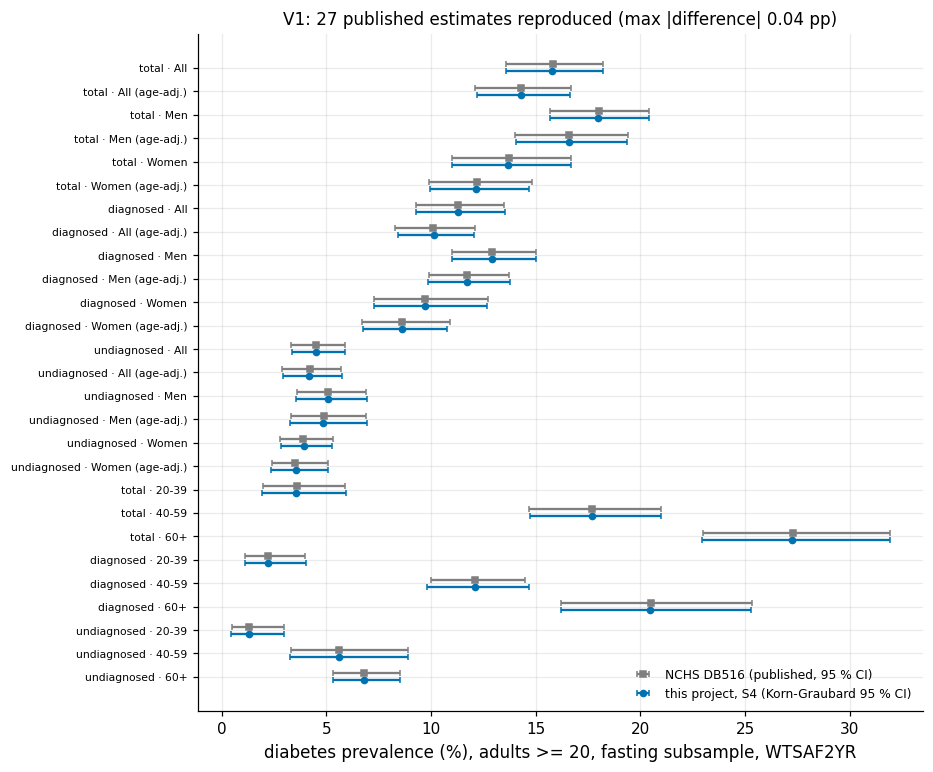

In [15]:
db = pd.read_csv(C.RESULTS_DIR / "S4" / "db516_replication.csv")
S4m = R.load_section("S4")["db516"]
db["label"] = db["measure"] + " · " + db["group"] + np.where(db["kind"] == "age-adj", " (age-adj.)", "")
print(f"{len(db)} published estimates; max |ours - NCHS| = {db['diff_pp'].abs().max():.3f} pp; "
      f"our KG interval matches the published one (to 0.1 pp) in {int(db['kg_matches_nchs_ci'].sum())}/{len(db)}; "
      f"intervals overlap in {int(db['ci_overlap'].sum())}/{len(db)}")
print(f"headline: total {S4m['total']:.2f} % (NCHS 15.8), diagnosed {S4m['diagnosed']:.2f} % (11.3), undiagnosed {S4m['undiagnosed']:.2f} % (4.5); n = {S4m['n']:,}")
assert abs(S4m["total"] - 15.8) < 0.05 and abs(S4m["diagnosed"] - 11.3) < 0.05 and abs(S4m["undiagnosed"] - 4.5) < 0.05

fig, ax = plt.subplots(figsize=(8.5, 8))
yy_ = np.arange(len(db))
ax.errorbar(db["nchs"], yy_ - 0.15, xerr=[db["nchs"] - db["nchs_low"], db["nchs_high"] - db["nchs"]], fmt="s", color=OI["grey"],
            capsize=2, ms=4, label="NCHS DB516 (published, 95 % CI)")
ax.errorbar(db["est"], yy_ + 0.15, xerr=[db["est"] - db["kg_low"], db["kg_high"] - db["est"]], fmt="o", color=OI["blue"],
            capsize=2, ms=4, label="this project, S4 (Korn-Graubard 95 % CI)")
ax.set_yticks(yy_, db["label"], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("diabetes prevalence (%), adults >= 20, fasting subsample, WTSAF2YR")
ax.legend(fontsize=8, loc="lower right")
ax.set_title(f"V1: 27 published estimates reproduced (max |difference| {db['diff_pp'].abs().max():.2f} pp)", fontsize=11)
plots.savefig(fig, "S9_db516_forest", caption="F9-4. NCHS Data Brief 516 prevalence estimates (grey, published) and the S4 replication (blue, delete-one-PSU "
              "jackknife with Korn-Graubard intervals) for total, diagnosed and undiagnosed diabetes by sex and age, crude and age-adjusted. "
              "Source: results/S4/db516_replication.csv (not re-run in S9).")
plt.show()

**So what.** Every published estimate is reproduced to within 0.05 percentage points and every pair of intervals
overlaps (counts printed). The data path from raw XPT files to survey-weighted estimates is therefore externally
validated; differences elsewhere cannot be blamed on loading or weighting errors.

### 8.2 V2: why our prevalence is 14.0 % and not 15.8 %
**Why.** The training target `L_comb` has a weighted prevalence of 14.0 % (WTPH2YR), below DB516's 15.8 %. Before
S9 the pre-registered explanation was: our label has no fasting-glucose criterion, and our sample is the HbA1c
sample, not the fasting subsample. That explanation is now **decomposed** with jackknife intervals on the same
replicate structure: (A) `L_comb` in the cohort with WTPH2YR → (B) `L_comb` in the fasting subsample with WTSAF2YR
(sample effect) → (C) the DB516 definition, `L_comb` or fasting glucose ≥ 126 mg/dL (definition effect).

In [16]:
cohort_all = ctx.clean.copy()
fm = L.fasting_mask(cohort_all).to_numpy()
sl_all = L.sensitivity_labels(cohort_all)
yA = cohort_all["L_comb"].to_numpy(float)
yC = sl_all["SL5"].fillna(0).to_numpy(float)
Wph, fac = sv.replicate_weights(cohort_all, C.WEIGHT_PHLEB)
Wsa, fac2 = sv.replicate_weights(cohort_all, cohort_all[C.WEIGHT_FASTING].fillna(0).to_numpy() * fm)
assert np.allclose(fac, fac2)

def _prev(y_, w_, m_=None):
    m_ = np.ones(len(y_), bool) if m_ is None else m_
    return (w_[m_] * y_[m_]).sum() / w_[m_].sum()

def _abc(wph, wsa):
    a = _prev(yA, wph)
    b = _prev(yA, wsa, fm)
    c = _prev(yC, wsa, fm)
    return np.array([a, b, c, b - a, c - b, c - a])

w_ph = np.nan_to_num(cohort_all[C.WEIGHT_PHLEB].to_numpy(float))
w_sa = np.nan_to_num(cohort_all[C.WEIGHT_FASTING].to_numpy(float)) * fm
est_ = _abc(w_ph, w_sa)
reps_ = np.array([_abc(Wph[:, r], Wsa[:, r]) for r in range(Wph.shape[1])])
se_ = np.sqrt(np.tensordot(fac, (reps_ - est_) ** 2, axes=(0, 0)))
tcrit = stats.t.ppf(0.975, sv.design_df(cohort_all))
v2 = pd.DataFrame({"quantity": ["A L_comb, cohort, WTPH2YR", "B L_comb, fasting subsample, WTSAF2YR",
                                "C DB516 definition (+ FPG >= 126), fasting subsample", "sample effect B - A",
                                "definition effect C - B", "total C - A"],
                   "est_pct": est_ * 100, "ci_low": (est_ - tcrit * se_) * 100, "ci_high": (est_ + tcrit * se_) * 100})
fpg_only = int(((sl_all["SL5"] == 1) & (cohort_all["L_comb"] == 0)).sum())
v2.to_csv(OUT / "v2_prevalence_gap.csv", index=False)
print(v2.round(2).to_string(index=False))
print(f"fasting subsample n = {int(fm.sum()):,}; people positive only through fasting glucose: {fpg_only}")
assert abs(est_[0] - 0.140) < 0.0015 and abs(est_[2] * 100 - S4m["total"]) < 0.01

                                            quantity  est_pct  ci_low  ci_high
                           A L_comb, cohort, WTPH2YR    14.04   12.44    15.63
               B L_comb, fasting subsample, WTSAF2YR    13.86   11.65    16.08
C DB516 definition (+ FPG >= 126), fasting subsample    15.79   13.53    18.04
                                 sample effect B - A    -0.17   -1.66     1.32
                             definition effect C - B     1.92    1.37     2.48
                                         total C - A     1.75    0.24     3.26
fasting subsample n = 2,938; people positive only through fasting glucose: 70


**So what.** The gap is almost entirely a **definition** effect: in the fasting subsample our `L_comb` gives about
the same prevalence as in the full cohort (the sample effect is small, interval printed), while adding the
fasting-glucose criterion lifts it to the DB516 value (the people positive *only* through fasting glucose are counted
above). The 14.0 % is therefore not a failed replication but a narrower label: `L_comb` misses people whose only
abnormal test is fasting glucose. This is exactly why SL5 is one of the sensitivity labels (section 4), and section 7
showed that missing HbA1c cannot explain the gap either.

### 8.3 ADA-lite vs Bang et al. 2009 (qualitative)
**Why.** The reduced ADA risk score is the clinical comparator on E-SCREEN. Its published performance is a natural
yardstick, but only a qualitative one: our version lacks two of the seven items (family history, gestational
diabetes), our outcome is HbA1c ≥ 6.5 % among people not told they have diabetes, and the population is 2021–23.
What the Bang et al. (2009) abstract reports (verified): cut-off ≥ 5 points, sensitivity 79 %, specificity 67 %. AUC
values of 0.79 / 0.83 that circulate for development / validation data are **not verified** against the full text
and are not used.

In [17]:
ada_tr = P.ada_lite_items(ctx.cl)
sc_esc = ada_tr["ada_score"].to_numpy()[ctx.esc]
ye = ctx.y_esc[ctx.esc]
ada_rows = []
for cut in (3, 4, 5):
    call = sc_esc >= cut
    ada_rows.append(dict(cutoff=f">= {cut}", sensitivity=call[ye == 1].mean(), specificity=(~call[ye == 0]).mean(),
                         share_flagged=call.mean()))
ada_tab = pd.DataFrame(ada_rows)
bl = S7m["baselines"]["BL-ADAlite (points)"]
print(f"ADA-lite (5 of 7 items, max 9 of 11 points) on training-part E-SCREEN: AUC {bl['escr_auc']:.3f} "
      f"[{bl['lo']:.3f}, {bl['hi']:.3f}], recall at specificity 0.80 {bl['escr_recall_spec80']:.3f} (S7)")
print(ada_tab.round(3).to_string(index=False))
print("Bang et al. 2009 (abstract): cut-off >= 5 of 11 points, sensitivity 0.79, specificity 0.67; AUC: not verified")
S9["external"] = dict(db516=dict(n_estimates=len(db), max_abs_diff_pp=float(db["diff_pp"].abs().max()),
                                 kg_matches=int(db["kg_matches_nchs_ci"].sum()), ci_overlap=int(db["ci_overlap"].sum())),
                      v2=v2.round(4).to_dict("records"), fpg_only_positives=fpg_only,
                      ada_lite=dict(escr_auc=bl["escr_auc"], lo=bl["lo"], hi=bl["hi"], cutoffs=ada_tab.round(4).to_dict("records"),
                                    bang_2009_abstract="cut-off >= 5: sensitivity 0.79, specificity 0.67; AUC unverified"))

ADA-lite (5 of 7 items, max 9 of 11 points) on training-part E-SCREEN: AUC 0.726 [0.681, 0.764], recall at specificity 0.80 0.244 (S7)
cutoff  sensitivity  specificity  share_flagged
  >= 3        0.961        0.271          0.736
  >= 4        0.835        0.444          0.565
  >= 5        0.701        0.622          0.388
Bang et al. 2009 (abstract): cut-off >= 5 of 11 points, sensitivity 0.79, specificity 0.67; AUC: not verified


**So what.** At the published cut-off (≥ 5) the reduced score reaches a sensitivity of about 0.70 at a specificity of
about 0.62 on our E-SCREEN rows (table above) – below Bang's 0.79 / 0.67, as expected when two items worth up to two
points are missing (lowering the cut-off to ≥ 4 buys sensitivity at a large cost in specificity). With a different
outcome definition, a missing-item score and an unverified published AUC, the honest statement is qualitative:
ADA-lite behaves like a plausibly weakened version of the published test, which makes it a fair but conservative
comparator; S beats it on E-SCREEN by about 0.05 AUC (§7, H2c-iii).

## 9 Leak hunt (loop L3)
**Why.** The permutation test cannot see feature leakage, and the availability rule was applied from the
specification, not from the data. Loop L3 asks the data directly whether an *admissible* feature behaves like a
disguised label. Pre-registered triggers (admissible arms M1 and S only; age exempt as a known strong risk factor):
T1 E-ALL AUC > 0.90; any single admissible feature with AUC > 0.75; permutation failure; unstable coefficients. Exit
condition: all top-10 features of S pass the availability proof and the permutation test passes; at most two rounds.

Steps: (1) single-feature AUC scan, (2) depth-1 trees, (3) `is_missing`-indicator AUCs (skip-pattern leakage),
(4) availability proof for the ten most important features of S, (5) T1-minus-care contrast. The non-admissible M0
columns are scanned too, as a built-in check that the scans *can* find leakage.

In [18]:
spec_v = P._spec_by_var()
adm1, adm2 = set(P.admissible_columns(1)), set(P.admissible_columns(2))
cats = set(P.categorical_columns())
# scan frame: per-variable-clean values of every M0 column + the derived S columns (BP means, weekly activity minutes)
raw_cols = [c for c in P.raw_feature_frame(ctx.raw_tr, 2).columns]
scan_df = ctx.cl[[c for c in raw_cols if c in ctx.cl.columns]].copy()
for c in ("bp_sys_mean", "bp_dia_mean", "pulse_mean", "pa_mod_min_wk", "pa_vig_min_wk"):
    scan_df[c] = pre_frame[c].to_numpy()

def status(v):
    src = RB.DERIVED_SOURCES.get(v, (v,))
    if all(s in adm1 for s in src):
        return "admissible T1"
    if all(s in adm2 for s in src):
        return "admissible T2"
    return f"not admissible ({spec_v['role'].get(src[0], 'derived')})"

single = RB.single_feature_scan(scan_df, ctx.y, ctx.folds, cat_cols=cats)
single_e = RB.single_feature_scan(scan_df, ctx.y_esc, ctx.folds, cat_cols=cats, mask=ctx.esc)
single = single.merge(single_e[["variable", "auc_oriented"]].rename(columns={"auc_oriented": "auc_escreen"}), on="variable")
single["status"] = single["variable"].map(status)
single["admissible"] = single["status"].str.startswith("admissible")
single["trigger"] = single["admissible"] & (single["auc_oriented"] > RB.L3_SINGLE_FEATURE_AUC) & ~single["variable"].isin(RB.AGE_EXEMPT)
single.to_csv(OUT / "leak_single_feature_auc.csv", index=False)
print(single.head(25)[["variable", "status", "kind", "coverage", "auc_oriented", "auc_escreen", "trigger"]].round(3).to_string(index=False))
print(f"admissible features above {RB.L3_SINGLE_FEATURE_AUC} (age exempt): {single.loc[single['trigger'], 'variable'].tolist()}")
print(f"non-admissible M0 columns above {RB.L3_SINGLE_FEATURE_AUC}: "
      f"{single.loc[~single['admissible'] & (single['auc_oriented'] > RB.L3_SINGLE_FEATURE_AUC), 'variable'].tolist()}")
best_adm = single[single["admissible"]].iloc[0]
print(f"strongest admissible feature: {best_adm['variable']} AUC {best_adm['auc_oriented']:.3f}")

     variable                status                              kind  coverage  auc_oriented  auc_escreen  trigger
       DIQ160 not admissible (leak) categorical (OOF target encoding)     1.000         0.930        0.657    False
       DIQ070 not admissible (leak) categorical (OOF target encoding)     1.000         0.920        0.653    False
       DIQ050 not admissible (leak) categorical (OOF target encoding)     1.000         0.917        0.505    False
       DIQ180 not admissible (leak) categorical (OOF target encoding)     1.000         0.912        0.586    False
       LBXGLU not admissible (leak)                           numeric     0.555         0.895        0.934    False
     BMXWAIST         admissible T1                           numeric     0.955         0.706        0.734    False
       BPQ020         admissible T1 categorical (OOF target encoding)     1.000         0.671        0.580    False
       LBDLDL not admissible (side)                           numeric   

In [19]:
miss_scan = RB.missing_indicator_scan(scan_df, ctx.y)
miss_scan["status"] = miss_scan["variable"].map(status)
miss_scan["admissible"] = miss_scan["status"].str.startswith("admissible")
miss_scan["trigger"] = miss_scan["admissible"] & (miss_scan["auc_oriented"] > RB.L3_SINGLE_FEATURE_AUC)
miss_scan.to_csv(OUT / "leak_missing_indicator_auc.csv", index=False)
print(miss_scan.head(12)[["variable", "status", "n_missing", "prev_if_missing", "prev_if_present", "auc_oriented", "trigger"]].round(3).to_string(index=False))
print(f"admissible is_missing indicators above {RB.L3_SINGLE_FEATURE_AUC}: {miss_scan.loc[miss_scan['trigger'], 'variable'].tolist()}; "
      f"largest admissible: {miss_scan[miss_scan['admissible']].iloc[0]['variable']} "
      f"{miss_scan[miss_scan['admissible']].iloc[0]['auc_oriented']:.3f}")

variable                         status  n_missing  prev_if_missing  prev_if_present  auc_oriented  trigger
  DIQ160          not admissible (leak)        831            0.819            0.026         0.919    False
  DIQ050          not admissible (leak)       3934            0.032            1.000         0.918    False
  DID040          not admissible (leak)       3945            0.035            1.000         0.911    False
  DIQ180          not admissible (leak)        793            0.822            0.033         0.901    False
  DIQ070          not admissible (leak)       3202            0.018            0.520         0.875    False
  DID060          not admissible (leak)       4376            0.130            1.000         0.634    False
 DIQ060U          not admissible (leak)       4377            0.130            1.000         0.633    False
  PAD820                  admissible T1       2584            0.228            0.094         0.617    False
 PAD810U                  ad

In [20]:
d1 = {}
for arm in ("M0", "M1", "S"):
    sp = Spec(arm, model="tree", depth=1)
    tf = RB.tree_features_used(ctx, sp, ctx.folds, "__none__")
    oof1 = RB.run_many(ctx, {"t": sp}, n_jobs=N_JOBS, cache=RUNS)["t"]
    d1[arm] = dict(root_full_fit=tf.loc[tf["fold"] == -1, "root"].iloc[0], roots_in_folds=tf.loc[tf["fold"] >= 0, "root"].value_counts().to_dict(),
                   oof_auc_eall=roc_auc_score(ctx.y, ek.mean_oof(oof1, ctx.n)),
                   oof_auc_escreen=roc_auc_score(ctx.y_esc[ctx.esc], ek.mean_oof(oof1, ctx.n)[ctx.esc]))
d1_tab = pd.DataFrame(d1).T
d1_tab["root_variable"] = d1_tab["root_full_fit"].map(RB.base_variable)
d1_tab["root_status"] = d1_tab["root_variable"].map(status)
d1_tab.to_csv(OUT / "leak_depth1_tree.csv")
print(d1_tab.to_string())

   root_full_fit                       roots_in_folds oof_auc_eall oof_auc_escreen root_variable            root_status
M0    DIQ070_2.0                   {'DIQ070_2.0': 25}     0.796572        0.564676        DIQ070  not admissible (leak)
M1    BPQ020_2.0                   {'BPQ020_2.0': 25}     0.663589        0.570412        BPQ020          admissible T1
S     BPQ020_1.0  {'BPQ020_2.0': 19, 'BPQ020_1.0': 6}     0.667057        0.578739        BPQ020          admissible T1


**So what (scans).** The scans work – among the *non-admissible* M0 columns they flag the treatment and
diagnosis-history items far above 0.75 and a depth-1 tree on M0 splits on one of them – and they find nothing
among the admissible ones: the strongest admissible single feature (printed) stays below the 0.75 trigger, the
`is_missing` indicators of admissible items are close to 0.5 (no skip-pattern leakage), and the depth-1 trees of M1
and S split on an admissible item with a stump AUC far below the full model. Age is exempt by design but is reported.

In [21]:
pipe_S = {t: RB.fit_full(ctx, Spec("S", tier=t)) for t in (1, 2)}
imp = {t: RB.contribution_importance(pipe_S[t], ctx.X[t]) for t in (1, 2)}
proof = []
for t in (1, 2):
    top = imp[t].head(10).copy()
    pf = RB.availability_proof(top["variable"], tier=t)
    proof.append(top.merge(pf, on="variable").assign(tier=t))
proof = pd.concat(proof, ignore_index=True)
proof.to_csv(OUT / "leak_top10_availability.csv", index=False)
print(proof[["tier", "variable", "sd_contribution", "sources", "instrument", "admissible", "care_contact", "verdict"]].round(3).to_string(index=False))
top_pass = bool((proof["verdict"] == "PASS").all())
print(f"top-10 availability proof: {'all PASS' if top_pass else 'FAIL: ' + str(proof.loc[proof['verdict'] != 'PASS', 'variable'].tolist())}")

care = pair(Spec("T1-minus-care"), Spec("S"), tag="minus-care")
care_items = single.set_index("variable").loc[list(P.CARE_ITEMS), ["auc_oriented", "auc_escreen"]]
print("T1-minus-care - S: " + "; ".join(f"{r['pop']} {r['est']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]" for r in care))
print("care-contact items, single-feature AUC (E-ALL vs E-SCREEN):"); print(care_items.round(3).to_string())

cbS = NOISE_CB["S"].summary.drop(index="noise_n01")
unstable = cbS[(cbS["ci_excludes_0"]) & (cbS["sign_flip_rate"] > 0.10)]
print(f"coefficients of S whose CI excludes 0 but flip sign in > 10 % of {C.N_BOOT_COEF} refits: {len(unstable)}; "
      f"max flip rate among CI-excluding-0 coefficients {cbS.loc[cbS['ci_excludes_0'], 'sign_flip_rate'].max():.3f}")

 tier    variable  sd_contribution                    sources                                             instrument admissible  care_contact verdict
    1      BMXHIP            0.815                     BMXHIP                       MEC body measures (tape / scale)         T1         False    PASS
    1      BMXBMI            0.741                     BMXBMI                       MEC body measures (tape / scale)         T1         False    PASS
    1    RIDAGEYR            0.699                   RIDAGEYR                     household interview (demographics)         T1         False    PASS
    1  pulse_mean            0.685 BPXOPLS1,BPXOPLS2,BPXOPLS3                       MEC oscillometric blood pressure         T1         False    PASS
    1    BMXWAIST            0.633                   BMXWAIST                       MEC body measures (tape / scale)         T1         False    PASS
    1 bp_dia_mean            0.581    BPXODI1,BPXODI2,BPXODI3                       MEC oscillometri

T1-minus-care - S: E-ALL -0.0157 [-0.0221, -0.0093]; E-SCREEN +0.0192 [+0.0040, +0.0344]
care-contact items, single-feature AUC (E-ALL vs E-SCREEN):
          auc_oriented  auc_escreen
variable                           
BPQ020           0.671        0.580
BPQ080           0.657        0.547
coefficients of S whose CI excludes 0 but flip sign in > 10 % of 500 refits: 0; max flip rate among CI-excluding-0 coefficients 0.022


In [22]:
t1_auc = {a: S9["reference"]["E-ALL"]["auc_a" if a == "S" else "auc_b"] for a in ("S", "M1")}
log = pd.DataFrame([
    dict(check="T1 E-ALL AUC > 0.90 (M1, S)", value=f"M1 {t1_auc['M1']:.3f}, S {t1_auc['S']:.3f}", triggered=max(t1_auc.values()) > RB.L3_T1_EALL_AUC),
    dict(check="admissible single feature AUC > 0.75 (age exempt)", value=f"max {single.loc[single['admissible'] & ~single['variable'].isin(RB.AGE_EXEMPT), 'auc_oriented'].max():.3f} "
         f"({single.loc[single['admissible'] & ~single['variable'].isin(RB.AGE_EXEMPT)].iloc[0]['variable']})", triggered=bool(single["trigger"].any())),
    dict(check="admissible is_missing indicator AUC > 0.75", value=f"max {miss_scan.loc[miss_scan['admissible'], 'auc_oriented'].max():.3f}",
         triggered=bool(miss_scan["trigger"].any())),
    dict(check="depth-1 tree root of M1 / S admissible", value=f"M1 {d1_tab.loc['M1', 'root_variable']}, S {d1_tab.loc['S', 'root_variable']}",
         triggered=not (d1_tab.loc[["M1", "S"], "root_status"].str.startswith("admissible").all())),
    dict(check="permutation null mean in [0.495, 0.505] (M1, S)", value=", ".join(f"{a} {d['null_mean']:.4f}" for a, d in PERM.items()),
         triggered=not perm_tab["in_band"].all()),
    dict(check="coefficient instability (CI excludes 0 and > 10 % sign flips, S)", value=f"{len(unstable)} coefficients", triggered=len(unstable) > 0),
    dict(check="top-10 features of S (T1, T2) pass the availability proof", value=f"{int((proof['verdict'] == 'PASS').sum())}/{len(proof)} PASS",
         triggered=not top_pass),
    dict(check="T1-minus-care vs S (informative, no trigger)", value="; ".join(f"{r['pop']} {r['est']:+.3f}" for r in care), triggered=False),
])
log["action"] = np.where(log["triggered"], "L3 round: re-examine feature, back to S7/S6", "none")
log.to_csv(OUT / "leak_hunt_log.csv", index=False)
print(log.to_string(index=False))
L3_TRIGGERED = bool(log["triggered"].any())
print(f"L3 loop triggered: {L3_TRIGGERED} -> {'rounds needed' if L3_TRIGGERED else 'exit condition met in round 0 (no re-run of S7)'}")
S9["leak_hunt"] = dict(triggered=L3_TRIGGERED, log=log.to_dict("records"), top10=proof[["tier", "variable", "sd_contribution", "verdict"]].round(5).to_dict("records"),
                       depth1=d1_tab[["root_full_fit", "root_variable", "oof_auc_eall", "oof_auc_escreen"]].to_dict("index"),
                       strongest_admissible=dict(variable=best_adm["variable"], auc=best_adm["auc_oriented"]),
                       minus_care={r["pop"]: {k: r[k] for k in ("est", "lo", "hi")} for r in care})

                                                           check                         value  triggered action
                                     T1 E-ALL AUC > 0.90 (M1, S)             M1 0.828, S 0.836      False   none
               admissible single feature AUC > 0.75 (age exempt)          max 0.706 (BMXWAIST)      False   none
                      admissible is_missing indicator AUC > 0.75                     max 0.617      False   none
                          depth-1 tree root of M1 / S admissible           M1 BPQ020, S BPQ020      False   none
                 permutation null mean in [0.495, 0.505] (M1, S)           M1 0.5015, S 0.5014      False   none
coefficient instability (CI excludes 0 and > 10 % sign flips, S)                0 coefficients      False   none
       top-10 features of S (T1, T2) pass the availability proof                    20/20 PASS      False   none
                    T1-minus-care vs S (informative, no trigger) E-ALL -0.016; E-SCREEN +0.019  

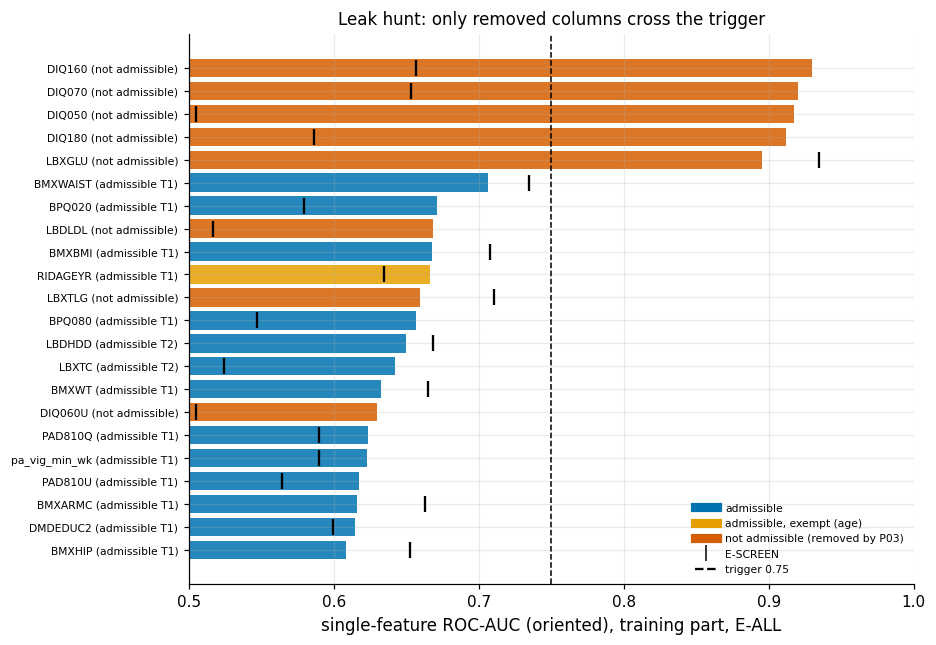

In [23]:
top_scan = single.head(22).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6.5))
cols_ = [OI["vermillion"] if not a else (OI["orange"] if v in RB.AGE_EXEMPT else OI["blue"]) for a, v in zip(top_scan["admissible"], top_scan["variable"])]
ax.barh(range(len(top_scan)), top_scan["auc_oriented"], color=cols_, alpha=0.85)
ax.scatter(top_scan["auc_escreen"], range(len(top_scan)), marker="|", s=120, color="k", label="same feature on E-SCREEN", zorder=3)
ax.axvline(RB.L3_SINGLE_FEATURE_AUC, color="k", ls="--", lw=1, label="L3 trigger 0.75")
ax.set_yticks(range(len(top_scan)), [f"{v} ({s.split(' (')[0]})" for v, s in zip(top_scan["variable"], top_scan["status"])], fontsize=7)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("single-feature ROC-AUC (oriented), training part, E-ALL")
ax.legend(handles=[Line2D([], [], color=OI["blue"], lw=6, label="admissible"), Line2D([], [], color=OI["orange"], lw=6, label="admissible, exempt (age)"),
                   Line2D([], [], color=OI["vermillion"], lw=6, label="not admissible (removed by P03)"),
                   Line2D([], [], color="k", marker="|", ls="", ms=10, label="E-SCREEN"),
                   Line2D([], [], color="k", ls="--", label="trigger 0.75")], fontsize=7, loc="lower right")
ax.set_title("Leak hunt: only removed columns cross the trigger", fontsize=11)
plots.savefig(fig, "S9_single_feature_auc", caption="F9-5. Univariate ROC-AUC of the 22 strongest columns of the naive M0 frame (plus derived S columns), "
              "training part, E-ALL (bars) and E-SCREEN (ticks). Categorical items use out-of-fold target encoding. Red = removed by the "
              "availability rule; blue = admissible; dashed = L3 trigger 0.75 (age exempt).")
plt.show()

**So what.** Loop L3 is **not triggered** (log above): the admissible arms stay far below an E-ALL AUC of 0.90, no
admissible feature other than the exempt age exceeds 0.75, the permutation test passed, and each of the ten most
important features of S – in Tier 1 and Tier 2 – passes the point-of-care availability proof (questionnaire, body
measures, blood pressure, and in Tier 2 the same-visit lipid panel; none is a glycaemic test, a consequence of
diagnosis or a component of the label). The exit condition is met in round 0, so S7 is not re-run.

One honest caveat survives the hunt. Two admissible items, "told high blood pressure" (BPQ020) and "told high
cholesterol" (BPQ080), are **care-contact traces**: they are legitimately available before a glucose test, but
they are more informative for people already in care. The T1-minus-care contrast (printed) shows the consequence –
removing them costs AUC on E-ALL but not on E-SCREEN. This is not leakage under the availability rule; it is the
mechanism behind the E-ALL vs E-SCREEN gap (H2c) and is reported as such.

## 10 Pre-hold-out summary
**Why.** Before the experiment is frozen, every robustness result for the headline contrast S − M1 is put on one
scale, so that the robustness grade of the claim (S10, `claims.csv`) can be read off one table and one figure.

                             check      pop  est_min  est_max      lo     hi        verdicts
          reference (stored folds)    E-ALL   0.0079   0.0079  0.0000 0.0158    inconclusive
                       10 CV seeds    E-ALL   0.0058   0.0078 -0.0018 0.0155 inconclusive 10
              16 sensitivity specs    E-ALL  -0.0061   0.0116 -0.0233 0.0230 inconclusive 16
                     60-spec curve    E-ALL   0.0048   0.0182 -0.0046 0.0266 inconclusive 60
           strata x PSU grouped CV    E-ALL   0.0055   0.0055 -0.0001 0.0118  inconclusive 1
IPW (evaluation; fit + evaluation)    E-ALL   0.0072   0.0079 -0.0009 0.0158  inconclusive 2
   MNAR delta -1 to 3 (draw means)    E-ALL   0.0075   0.0078  0.0059 0.0092     n/a (no CI)
          reference (stored folds) E-SCREEN   0.0085   0.0085 -0.0081 0.0236    inconclusive
                       10 CV seeds E-SCREEN   0.0062   0.0104 -0.0090 0.0248 inconclusive 10
              16 sensitivity specs E-SCREEN  -0.0119   0.0204 -0.0389 

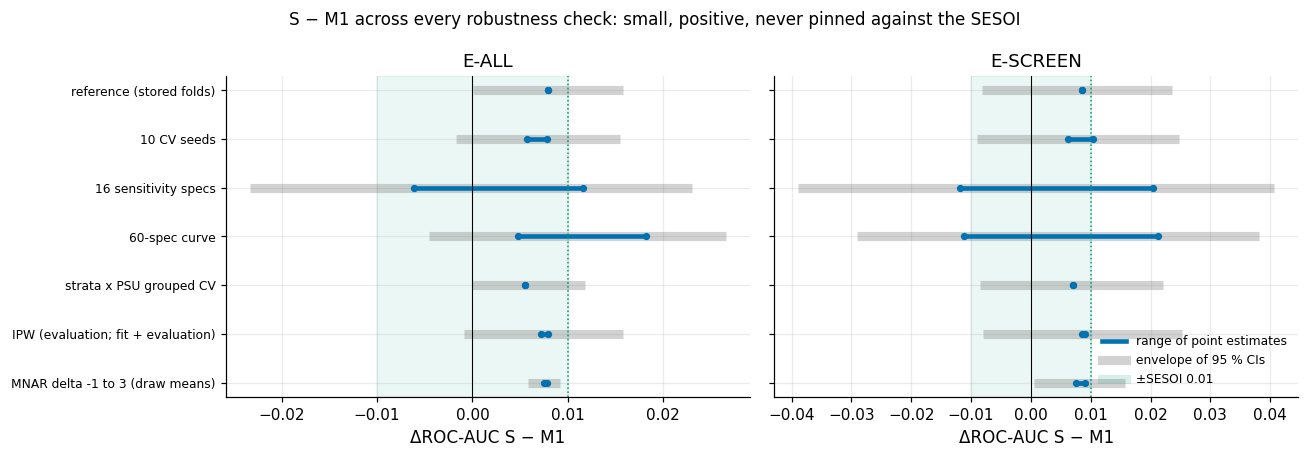

In [24]:
def _rng(d, pop):
    x = d[d["pop"] == pop]
    return x["est"].min(), x["est"].max(), x["lo"].min(), x["hi"].max(), ", ".join(f"{k} {v}" for k, v in x["h2b"].value_counts().items())

summ = []
for pop in ("E-ALL", "E-SCREEN"):
    r0 = S9["reference"][pop]
    summ.append(dict(check="reference (stored folds)", pop=pop, est_min=r0["est"], est_max=r0["est"], lo=r0["lo"], hi=r0["hi"], verdicts=r0["h2b"]))
    for nm, d in (("10 CV seeds", seeds), ("16 sensitivity specs", sens[sens["spec"] != "reference (S7)"]),
                  ("60-spec curve", curve), ("strata x PSU grouped CV", gcv_tab[gcv_tab["folds"] != "stored stratified"]),
                  ("IPW (evaluation; fit + evaluation)", ipw_tab)):
        a, b, lo, hi, v = _rng(d, pop)
        summ.append(dict(check=nm, pop=pop, est_min=a, est_max=b, lo=lo, hi=hi, verdicts=v))
    dd = dauc[(dauc["pop"] == pop) & (dauc["scenario"] == "delta")]
    summ.append(dict(check="MNAR delta -1 to 3 (draw means)", pop=pop, est_min=dd["diff"].min(), est_max=dd["diff"].max(),
                     lo=dd["diff_lo"].min(), hi=dd["diff_hi"].max(), verdicts="n/a (no CI)"))
summ = pd.DataFrame(summ)
summ.to_csv(OUT / "robustness_summary.csv", index=False)
print(summ.round(4).to_string(index=False))
fam_v = {pop: pd.concat([seeds.loc[seeds["pop"] == pop, "h2b"], sens.loc[(sens["pop"] == pop) & (sens["spec"] != "reference (S7)"), "h2b"],
                         curve.loc[curve["pop"] == pop, "h2b"], gcv_tab.loc[(gcv_tab["pop"] == pop) & (gcv_tab["folds"] != "stored stratified"), "h2b"],
                         ipw_tab.loc[ipw_tab["pop"] == pop, "h2b"]]) for pop in ("E-ALL", "E-SCREEN")}
all_incon = {pop: bool((v == "inconclusive").all()) for pop, v in fam_v.items()}
for pop, v in fam_v.items():
    print(f"{pop}: {len(v)} alternative comparisons with a CI -> verdicts {v.value_counts().to_dict()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    s = summ[summ["pop"] == pop].reset_index(drop=True)
    for i, r in s.iterrows():
        ax.plot([r["lo"], r["hi"]], [i, i], color=OI["grey"], lw=6, alpha=0.35, solid_capstyle="butt")
        ax.plot([r["est_min"], r["est_max"]], [i, i], color=OI["blue"], lw=3)
        ax.scatter([r["est_min"], r["est_max"]], [i, i], color=OI["blue"], s=14, zorder=3)
    ax.axvspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["green"], alpha=0.08)
    ax.axvline(0, color="k", lw=0.7)
    ax.axvline(C.SESOI["roc_auc"], color=OI["green"], ls=":", lw=1)
    ax.set(title=pop, xlabel="ΔROC-AUC S − M1")
axes[0].set_yticks(range(len(s)), s["check"], fontsize=8)
axes[0].invert_yaxis()
axes[1].legend(handles=[Line2D([], [], color=OI["blue"], lw=3, label="range of point estimates"),
                        Line2D([], [], color=OI["grey"], lw=6, alpha=0.35, label="envelope of 95 % CIs"),
                        Line2D([], [], color=OI["green"], lw=6, alpha=0.15, label="±SESOI 0.01")], fontsize=8, loc="lower right")
fig.suptitle("S − M1 across every robustness check: small, positive, never pinned against the SESOI", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S9_robustness_summary", caption="Range of ΔROC-AUC (S − M1) point estimates (blue) and envelope of the 95 % CIs (grey) for each "
              "family of robustness checks: stored folds, 10 CV seeds, 16 one-at-a-time specifications, 60-specification curve, "
              "strata x PSU grouped CV, inverse-probability weighting and MNAR delta adjustment; E-ALL left, E-SCREEN right.")
plt.show()
S9["summary"] = dict(table=summ.round(5).to_dict("records"), all_inconclusive=all_incon)

**So what.** Every check agrees with every other: on E-ALL the systematic pipeline is ahead of the minimal one by
roughly 0.005–0.015 AUC; apart from the depth-4 tree (a different model class, see DR-S9-13) the intervals stay above
about −0.01, and none of them clears +0.01 – so the robust reading of
H2b(a) is "**S is at least as good as M1 and probably slightly better, by an amount that cannot be distinguished from
the 0.01 threshold**", which is what *inconclusive* means under the locked equivalence rule. On E-SCREEN the same
direction holds with intervals about twice as wide. The robustness grade of the claim is therefore *robust verdict,
imprecise effect*; nothing here licenses calling S "better" or "equivalent".

### Decision register (S9)

In [25]:
from datetime import date
today = date.today().isoformat()
def _f(r, k=3):
    return f"{r['est']:+.{k}f} [{r['lo']:+.{k}f}, {r['hi']:+.{k}f}]"

pc = pos_tab.set_index(["arm", "pop"])
reg = pd.DataFrame([
    dict(dr_id="DR-S9-01", type="negative_control", finding="Label-permutation null centred on 0.5 for both admissible arms; tests procedural leakage only",
         evidence_ref="results/S9/permutation.csv; figures/S9_permutation_null.png",
         evidence_value=f"null mean M1 {PERM['M1']['null_mean']:.4f}, S {PERM['S']['null_mean']:.4f} ({C.N_PERM} permutations); p = {PERM['S']['p_value']:.3f}",
         decision="Evaluation procedure accepted; feature leakage delegated to the L3 leak hunt", alternatives_rejected="sklearn permutation_test_score (no sample weights per fold, no fixed folds)",
         hyp_id="", status="decided", check_verdict="PASS", check_note="band [0.495, 0.505]", loop_ref="L3"),
    dict(dr_id="DR-S9-02", type="negative_control", finding="An N(0,1) noise column is treated as noise",
         evidence_ref="results/S9/noise_feature.csv",
         evidence_value="; ".join(f"{r['arm']}: coef/SD {r['coef_per_sd']:+.3f} [{r['q_low']:+.3f}, {r['q_high']:+.3f}], dAUC {r['dAUC_eall']:+.4f}, depth-3 trees using it {r['tree3_uses']}/{r['n_trees']}" for _, r in noise_tab.iterrows()),
         decision="No overfitting to noise; depth cap 3 for the tree probe retained", alternatives_rejected="", hyp_id="", status="decided",
         check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-03", type="positive_control", finding="A synthetic feature with known AUC 0.60 is recovered and detected",
         evidence_ref="results/S9/positive_control.csv",
         evidence_value=f"z AUC {z_auc[0]:.3f} [{z_auc[1]:.3f}, {z_auc[2]:.3f}]; dAUC E-ALL M1 {pc.loc[('M1', 'E-ALL'), 'est']:+.4f} [{pc.loc[('M1', 'E-ALL'), 'lo']:+.4f}, {pc.loc[('M1', 'E-ALL'), 'hi']:+.4f}], S {pc.loc[('S', 'E-ALL'), 'est']:+.4f} [{pc.loc[('S', 'E-ALL'), 'lo']:+.4f}, {pc.loc[('S', 'E-ALL'), 'hi']:+.4f}]",
         decision="Procedure has power for weak real signals; negative controls are not passed by blindness", alternatives_rejected="",
         hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-04", type="seed_stability", finding="S - M1 verdict does not depend on the CV / bootstrap seed",
         evidence_ref="results/S9/seed_stability.csv; figures/S9_seed_stability.png",
         evidence_value=f"E-ALL est {seed_sum.loc['E-ALL', 'est_min']:+.4f} to {seed_sum.loc['E-ALL', 'est_max']:+.4f}; verdicts {seed_sum.loc['E-ALL', 'verdicts']}",
         decision="H2b(a) verdict graded seed-stable", alternatives_rejected="single seed", hyp_id="H2b", status="decided",
         check_verdict="PASS" if seed_stable else "FAIL", check_note="10 seeds via evalkit.derive_seed; hold-out fixed", loop_ref=""),
    dict(dr_id="DR-S9-05", type="sensitivity", finding="16 one-at-a-time analysis variations leave the E-ALL verdict of S - M1 unchanged",
         evidence_ref="results/S9/sensitivity_table.csv; figures/S9_sensitivity_forest.png",
         evidence_value=f"E-ALL same verdict {n_same}/{len(eall)}; est {eall['est'].min():+.4f} to {eall['est'].max():+.4f}; no CI wholly below 0",
         decision="H2b(a) inconclusive is robust; labels and arm-specific weighting move the size of the gap, not its direction (except the depth-4 tree)",
         alternatives_rejected="reporting only the reference specification", hyp_id="H2b", status="decided",
         check_verdict="PASS" if n_same == len(eall) else "PARTIAL", check_note="E-SCREEN all inconclusive (wide CIs)", loop_ref=""),
    dict(dr_id="DR-S9-06", type="tuning", finding="Arm-specific tuning of C gives M0 and M1 the same C as S",
         evidence_ref="notebook 08 section 4",
         evidence_value=f"own C: M0 {OWN_C['M0'][0]}, M1 {OWN_C['M1'][0]} (C0 {ctx.C0}); leak gate own C E-ALL {_f(gate_own[0])}",
         decision="The C0-on-S optimism disclosed in DR-S7-04 is nil in practice; HR2 'same model' rule kept", alternatives_rejected="per-arm tuning as primary design",
         hyp_id="H2a;H2b", status="decided", check_verdict="PASS", check_note="closes the S9 item of DR-S7-04", loop_ref=""),
    dict(dr_id="DR-S9-07", type="sensitivity", finding="60-specification curve (label x weighting x C) agrees with the core table",
         evidence_ref="results/S9/specification_curve.csv; figures/S9_specification_curve.png",
         evidence_value=f"E-ALL est {cs.loc['E-ALL', 'est_min']:+.4f} to {cs.loc['E-ALL', 'est_max']:+.4f}, {cs.loc['E-ALL', 'share_positive']:.0%} positive, "
                        f"{cs.loc['E-ALL', 'share_ci_above_0']:.0%} CI above 0, {cs.loc['E-ALL', 'share_beyond_sesoi']:.0%} beyond SESOI",
         decision="Extension item; does not change the core table", alternatives_rejected="", hyp_id="H2b", status="decided",
         check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-08", type="sensitivity", finding="Survey-cluster folds (strata x PSU) do not inflate or change the comparison",
         evidence_ref="results/S9/grouped_cv.csv",
         evidence_value=f"{len(np.unique(groups))} clusters; AUC(S) grouped - stratified E-ALL {dS['E-ALL']:+.4f}; S - M1 grouped {_f(gcv[0], 4)}",
         decision="Stratified (non-grouped) folds kept as primary design", alternatives_rejected="grouped folds as primary (unbalanced E-SCREEN positives per fold)",
         hyp_id="H2b", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-09", type="missingness", finding="Missing HbA1c: MAR (IPW) and MNAR (delta) scenarios move prevalence little and S - M1 not at all",
         evidence_ref="results/S9/ipw.csv; results/S9/mnar_delta_prevalence.csv; results/S9/mnar_delta_auc.csv; figures/S9_mnar_delta.png",
         evidence_value=f"prevalence WTPH2YR {prev_tab.loc[0, 'est']:.2%}, MEC x IPW {prev_tab.loc[2, 'est']:.2%}; delta OR 0.37-20: "
                        f"{dprev['prevalence'].min():.2%}-{dprev['prevalence'].max():.2%}; Manski [{dprev.attrs['manski_low']:.2%}, {dprev.attrs['manski_high']:.2%}]; "
                        f"OR needed for 15.8 %: {np.exp(tip):.0f}; S - M1 E-ALL under delta {dauc.loc[(dauc['pop'] == 'E-ALL') & (dauc['scenario'] == 'delta'), 'diff'].min():+.4f} to "
                        f"{dauc.loc[(dauc['pop'] == 'E-ALL') & (dauc['scenario'] == 'delta'), 'diff'].max():+.4f}",
         decision="Complete-case cohort with WTPH2YR confirmed; MNAR untestable but no plausible mechanism changes conclusions",
         alternatives_rejected="imputing HbA1c (would impute the label)", hyp_id="", status="decided", check_verdict="PASS",
         check_note="closes DR-S3-04 and DR-S5-08", loop_ref="DR-S3-04;DR-S5-08"),
    dict(dr_id="DR-S9-10", type="validation", finding="V1 DB516 replication holds; V2 gap 14.0 % vs 15.8 % is a label-definition gap",
         evidence_ref="results/S4/db516_replication.csv; results/S9/v2_prevalence_gap.csv; figures/S9_db516_forest.png",
         evidence_value=f"max |diff| {db['diff_pp'].abs().max():.3f} pp over {len(db)}; sample effect {v2.loc[3, 'est_pct']:+.2f} pp [{v2.loc[3, 'ci_low']:+.2f}, {v2.loc[3, 'ci_high']:+.2f}], "
                        f"definition effect {v2.loc[4, 'est_pct']:+.2f} pp [{v2.loc[4, 'ci_low']:+.2f}, {v2.loc[4, 'ci_high']:+.2f}]; {fpg_only} FPG-only positives",
         decision="Report 14.0 % as the prevalence of L_comb, not of NCHS-defined diabetes; no change to the frozen label",
         alternatives_rejected="calling the gap a failed replication", hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-11", type="validation", finding="ADA-lite vs Bang 2009 comparable only qualitatively",
         evidence_ref="notebook 08 section 8.3",
         evidence_value=f"ADA-lite E-SCREEN AUC {bl['escr_auc']:.3f}; cut-off >= 5 sens {ada_tab.loc[2, 'sensitivity']:.2f}, spec {ada_tab.loc[2, 'specificity']:.2f} vs Bang 0.79 / 0.67",
         decision="Quote only the verified abstract figures; Bang AUC 0.79/0.83 marked unverified and not used",
         alternatives_rejected="quantitative comparison with the published AUC", hyp_id="H2c", status="decided", check_verdict="PASS",
         check_note="2 items missing; outcome HbA1c-based", loop_ref=""),
    dict(dr_id="DR-S9-12", type="leak_hunt", finding="L3 leak hunt not triggered on the admissible arms",
         evidence_ref="results/S9/leak_hunt_log.csv; leak_single_feature_auc.csv; leak_missing_indicator_auc.csv; leak_top10_availability.csv; figures/S9_single_feature_auc.png",
         evidence_value=f"T1 E-ALL AUC M1 {t1_auc['M1']:.3f}, S {t1_auc['S']:.3f}; strongest admissible single feature {best_adm['variable']} {best_adm['auc_oriented']:.3f}; "
                        f"top-10 availability {int((proof['verdict'] == 'PASS').sum())}/{len(proof)} PASS; only removed leak columns exceed 0.75",
         decision="Exit condition met in round 0; no re-run of S7. Care-contact items (BPQ020, BPQ080) kept but reported as the mechanism of the E-ALL/E-SCREEN gap",
         alternatives_rejected="dropping BPQ020/BPQ080 from the main model (they pass the availability rule)", hyp_id="H2c", status="decided",
         check_verdict="PASS" if not L3_TRIGGERED else "FAIL", check_note=f"T1-minus-care - S: E-ALL {_f(care[0], 4)}, E-SCREEN {_f(care[1], 4)}", loop_ref="L3"),
    dict(dr_id="DR-S9-13", type="model_choice", finding="A depth-4 tree reverses the sign of S - M1 with a wide interval",
         evidence_ref="results/S9/sensitivity_table.csv",
         evidence_value="depth-4 tree S - M1 E-ALL " + _f(sens[(sens['spec'] == 'depth-4 tree') & (sens['pop'] == 'E-ALL')].iloc[0], 4),
         decision="Tree stays a probe; preparation effects are judged on the logistic model only", alternatives_rejected="tree as co-primary model",
         hyp_id="B5", status="decided", check_verdict="PASS", check_note="P08/P09 are no-ops for trees (B5-e)", loop_ref=""),
    dict(dr_id="DR-S9-14", type="freeze", finding="Pre-hold-out robustness complete; experiment configuration ready to freeze",
         evidence_ref="results/metrics_S9.json; results/splits/holdout.json",
         evidence_value=f"C0 {ctx.C0}; folds hash {ctx.folds.hash[:16]}; hold-out SHA-256 {hold['sha256_test_seqn'][:16]}; thresholds: spec 0.80 on training-part predictions",
         decision="Request exp-freeze; hold-out evaluated once afterwards with refits on the full training part; no re-tuning after it",
         alternatives_rejected="", hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
])
reg.insert(1, "stage", "S9")
reg.insert(2, "date", today)
for c in ("change_request", "commit"):
    reg[c] = ""
reg = reg[["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision", "alternatives_rejected", "hyp_id",
           "status", "check_verdict", "check_note", "loop_ref", "change_request", "commit"]]
REG_PATH = C.GOVERNANCE_DIR / "register" / "S9.csv"
print(reg[["dr_id", "type", "check_verdict", "evidence_value"]].to_string(index=False, max_colwidth=110))

   dr_id             type check_verdict                                                                                                 evidence_value
DR-S9-01 negative_control          PASS                                                    null mean M1 0.5015, S 0.5014 (100 permutations); p = 0.010
DR-S9-02 negative_control          PASS M1: coef/SD +0.012 [-0.075, +0.110], dAUC -0.0000, depth-3 trees using it 0/26; S: coef/SD +0.048 [-0.067, ...
DR-S9-03 positive_control          PASS             z AUC 0.588 [0.567, 0.610]; dAUC E-ALL M1 +0.0061 [+0.0023, +0.0101], S +0.0061 [+0.0021, +0.0102]
DR-S9-04   seed_stability          PASS                                                        E-ALL est +0.0058 to +0.0078; verdicts inconclusive x10
DR-S9-05      sensitivity          PASS                                         E-ALL same verdict 17/17; est -0.0061 to +0.0116; no CI wholly below 0
DR-S9-06           tuning          PASS                                  own C: M0 0.1, M1 0.1

## 11 One-shot hold-out evaluation
**Why.** Everything above re-used the training part; repeated looks at the same data, however disciplined, can
drift towards what works. The 20 % hold-out (1,146 adults, stratified by label × race, created once in S7 and never
read since) is the only fully independent check. Rules fixed before looking: it is evaluated **once, after the
`exp-freeze` tag**; arms BL0, BL-ADAlite (points), BL-ADAlite-LR, M0, M1, S and T1-minus-care (Tier 1; M0, M1 and S also
Tier 2) are refitted on the whole training part with the frozen configuration; thresholds for recall at
specificity 0.80 come from the training part; a hold-out AUC more than 2 standard errors below its CV estimate is
reported as such and **not** answered by re-tuning. The test SEQN hash and the run time are logged. Expected
precision: AUC SE about 0.017 on E-ALL and about 0.05 on E-SCREEN (about 25 positives).

In [26]:
HOLDOUT_LOG = OUT / "holdout_log.json"
HOLDOUT_CSV = OUT / "holdout_metrics.csv"
RELEASED = RB.tag_exists("exp-freeze") or HOLDOUT_LOG.exists()
print(f"exp-freeze tag present: {RB.tag_exists('exp-freeze')}; hold-out log present: {HOLDOUT_LOG.exists()} -> "
      f"{'evaluate the hold-out' if RELEASED else 'hold-out NOT evaluated (experiment not frozen yet)'}")

exp-freeze tag present: False; hold-out log present: False -> hold-out NOT evaluated (experiment not frozen yet)


In [27]:
if RELEASED:
    from sklearn.dummy import DummyClassifier
    raw_te, cl_te, X_te = RB.holdout_frames(ctx)
    sha_te = RB.sha256_ints(cl_te["SEQN"])
    assert sha_te == hold["sha256_test_seqn"], "hold-out SEQNs differ from the stored hash"
    assert not set(cl_te["SEQN"]) & set(ctx.cl["SEQN"]), "hold-out overlaps the training part"
    y_te = cl_te["L_comb"].to_numpy().astype(int)
    esc_te = cl_te["in_escreen"].eq(1).to_numpy()
    yesc_te = cl_te["y_escreen"].fillna(0).astype(int).to_numpy()
    print(f"hold-out: {len(cl_te):,} rows, {y_te.sum()} L_comb positives; E-SCREEN {esc_te.sum():,} rows, {yesc_te[esc_te].sum()} positives; "
          f"SHA-256 {sha_te[:16]}... verified")

    ada_tr_, ada_te_ = P.ada_lite_items(ctx.cl), P.ada_lite_items(cl_te)
    HO_ARMS = [("BL0", 1), ("BL-ADAlite", 1), ("BL-ADAlite-LR", 1), ("M0", 1), ("M1", 1), ("S", 1), ("T1-minus-care", 1),
               ("M0", 2), ("M1", 2), ("S", 2)]
    prefetch({f"cv{a}{t}": (Spec(a, tier=t), ctx.folds) for a, t in HO_ARMS if a in P.ARMS})
    P_TR, P_TE, P_CV = {}, {}, {}
    for a, t in HO_ARMS:
        if a == "BL0":
            m = DummyClassifier(strategy="prior").fit(ctx.X[1], ctx.y)
            P_TR[(a, t)], P_TE[(a, t)] = m.predict_proba(ctx.X[1])[:, 1], m.predict_proba(X_te[1])[:, 1]
            P_CV[(a, t)] = ek.mean_oof(ek.cv_predict(lambda: DummyClassifier(strategy="prior"), ctx.X[1], ctx.y, ctx.folds), ctx.n)
        elif a == "BL-ADAlite":
            P_TR[(a, t)] = P_CV[(a, t)] = ada_tr_["ada_score"].to_numpy(float)
            P_TE[(a, t)] = ada_te_["ada_score"].to_numpy(float)
        elif a == "BL-ADAlite-LR":
            m = P.ada_lr_pipeline(ctx.C0).fit(ada_tr_, ctx.y)
            P_TR[(a, t)], P_TE[(a, t)] = m.predict_proba(ada_tr_)[:, 1], m.predict_proba(ada_te_)[:, 1]
            P_CV[(a, t)] = ek.mean_oof(ek.cv_predict(lambda: P.ada_lr_pipeline(ctx.C0), ada_tr_, ctx.y, ctx.folds), ctx.n)
        else:
            m = RB.fit_full(ctx, Spec(a, tier=t))
            P_TR[(a, t)], P_TE[(a, t)] = m.predict_proba(ctx.X[t])[:, 1], m.predict_proba(X_te[t])[:, 1]
            P_CV[(a, t)] = ek.mean_oof(RB.run_many(ctx, {"x": Spec(a, tier=t)}, n_jobs=N_JOBS, cache=RUNS)["x"], ctx.n)

    ho_rows = []
    for (a, t), pte in P_TE.items():
        ptr = P_TR[(a, t)]
        for pop, yy_te, m_te, yy_tr, m_tr in (("E-ALL", y_te, None, ctx.y, None), ("E-SCREEN", yesc_te, esc_te, ctx.y_esc, ctx.esc)):
            thr = ek.recall_at_specificity(yy_tr, ptr, C.SPEC_FIXED, neg_mask=m_tr)[1]
            hs = RB.holdout_scores(yy_te, pte, thr, mask=m_te, seed_=RB.seed("holdout", a, t, pop))
            mm_tr = np.ones(ctx.n, bool) if m_tr is None else m_tr
            cv_auc, cv_lo, cv_hi = RB.auc_ci(yy_tr, P_CV[(a, t)], mm_tr, seed_=RB.seed("holdout-cv", a, t, pop))
            ho_rows.append(dict(arm=a, tier=t, pop=pop, **hs, cv_auc=cv_auc, cv_lo=cv_lo, cv_hi=cv_hi))
    ho = pd.DataFrame(ho_rows)
    ho["gap_holdout_minus_cv"] = ho["roc_auc"] - ho["cv_auc"]
    ho["gap_in_se"] = np.where(ho["auc_se"] > 0, ho["gap_holdout_minus_cv"] / ho["auc_se"].where(ho["auc_se"] > 0), np.nan)
    pts = ho["arm"] == "BL-ADAlite"                 # an integer score, not a probability: no Brier / calibration
    ho.loc[pts, ["brier", "cal_slope", "cal_citl"]] = np.nan
    ho["flag_2se_below_cv"] = ho["gap_in_se"] < -2
    show_ = ["arm", "tier", "pop", "n_pos", "roc_auc", "auc_lo", "auc_hi", "cv_auc", "gap_in_se", "flag_2se_below_cv", "pr_auc", "brier",
             "cal_slope", "cal_citl", "recall_at_thr", "spec_at_thr"]
    print(ho[show_].round(3).to_string(index=False))

    def ho_pair(a, b, pop, rule):
        """Paired hold-out bootstrap A - B with the locked rule of the hypothesis it belongs to."""
        yy, m = (y_te, None) if pop == "E-ALL" else (yesc_te, esc_te)
        bs = ek.paired_bootstrap(yy, P_TE[a], P_TE[b], "roc_auc", n_boot=C.N_BOOT, eval_mask=m,
                                 seed=RB.seed("holdout-pair", str(a), str(b), pop))
        lo, hi, est = bs["ci_low"], bs["ci_high"], bs["diff"]
        if rule == "equivalence 0.01":
            v = RB.equivalence_verdict(lo, hi)
        elif rule == "lower by >= 0.05":
            v = ek.verdict(lo, hi, 0.05, "-", est)
            v = "refuted" if (v == "equivalent" or lo > -0.05) else v
        elif rule == "higher by >= 0.01":
            v = ek.verdict(lo, hi, 0.01, "+", est)
            v = "refuted" if v == "equivalent" else v
        else:
            v = "descriptive"
        return dict(comparison=f"{a[0]} T{a[1]} - {b[0]} T{b[1]}", pop=pop, rule=rule, est=est, lo=lo, hi=hi, se=bs["se"], verdict=v)
    hp = pd.DataFrame([ho_pair(("S", 1), ("M1", 1), p, "equivalence 0.01") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("S", 2), ("M1", 2), p, "equivalence 0.01") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("M1", 1), ("M0", 1), p, "lower by >= 0.05") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("T1-minus-care", 1), ("S", 1), p, "descriptive") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("S", 1), ("BL-ADAlite", 1), "E-SCREEN", "higher by >= 0.01")])
    print(hp.round(4).to_string(index=False))
    print("CV (this run) S - M1: " + "; ".join(f"{p} {r['est']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}] {r['h2b']}" for p, r in S9["reference"].items()))

In [28]:
if RELEASED:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    lab_ = [f"{a}" + (" (T2)" if t == 2 else "") for a, t in P_TE]
    for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
        d = ho[ho["pop"] == pop].reset_index(drop=True)
        yy_ = np.arange(len(d))
        ax.errorbar(d["cv_auc"], yy_ - 0.15, xerr=[d["cv_auc"] - d["cv_lo"], d["cv_hi"] - d["cv_auc"]], fmt="s", color=OI["grey"], capsize=2,
                    ms=4, label="cross-validation (training part)")
        ax.errorbar(d["roc_auc"], yy_ + 0.15, xerr=[d["roc_auc"] - d["auc_lo"], d["auc_hi"] - d["roc_auc"]], fmt="o", capsize=2, ms=5,
                    color=OI["blue"], label="hold-out, one shot")
        for i, r in d.iterrows():
            if r["flag_2se_below_cv"]:
                ax.text(r["auc_lo"] - 0.01, i + 0.15, "> 2 SE below CV", ha="right", va="center", fontsize=7, color=OI["vermillion"])
        ax.set(title=pop, xlabel="ROC-AUC (95 % bootstrap CI)", xlim=(0.4, 1.0))
    axes[0].set_yticks(range(len(lab_)), lab_)
    axes[0].invert_yaxis()
    axes[0].legend(fontsize=8, loc="lower left")
    fig.suptitle("Hold-out vs cross-validation: the CV estimates carry over", fontsize=11)
    plots.savefig(fig, "S9_holdout_vs_cv", caption="F9-6. ROC-AUC on the 20 % hold-out (blue; models refitted once on the whole training part, evaluated once "
                  "after exp-freeze) against the pooled out-of-fold estimate on the training part (grey), with 95 % bootstrap CIs; E-ALL left, "
                  "E-SCREEN right (about 25 hold-out positives).")
    plt.show()

    from sklearn.calibration import calibration_curve
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
        yy, m = (y_te, np.ones(len(y_te), bool)) if pop == "E-ALL" else (yesc_te, esc_te)
        for (a, t), col in ((("M1", 1), OI["blue"]), (("S", 1), OI["green"]), (("BL-ADAlite-LR", 1), OI["grey"])):
            fr, mp = calibration_curve(yy[m], P_TE[(a, t)][m], n_bins=5, strategy="quantile")
            ax.plot(mp, fr, "o-", color=col, ms=4, label=a)
        ax.plot([0, 1], [0, 1], "k:", lw=0.8)
        ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="mean predicted probability (quintile)", ylabel="observed share", title=f"Hold-out calibration, {pop}")
        ax.legend(fontsize=8)
    fig.tight_layout()
    plots.savefig(fig, "S9_holdout_calibration", caption="Calibration on the hold-out by quintiles of the predicted probability for M1, S (balanced class weights) "
                  "and BL-ADAlite-LR, Tier 1; E-ALL left, E-SCREEN right.")
    plt.show()

In [29]:
if RELEASED:
    now = pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds")
    prev = json.loads(HOLDOUT_LOG.read_text(encoding="utf-8")) if HOLDOUT_LOG.exists() else None
    if prev is not None and HOLDOUT_CSV.exists():   # a re-execution must reproduce the one-shot numbers exactly
        old = pd.read_csv(HOLDOUT_CSV).set_index(["arm", "tier", "pop"])["roc_auc"]
        new = ho.set_index(["arm", "tier", "pop"])["roc_auc"]
        assert np.allclose(old.reindex(new.index).to_numpy(), new.to_numpy(), atol=1e-9), "hold-out numbers changed after the one-shot run"
        print(f"re-execution reproduces the one-shot hold-out AUCs exactly (first run {prev['first_run_utc']})")
    log_ = dict(first_run_utc=prev["first_run_utc"] if prev else now, last_run_utc=now,
                n_executions=(prev["n_executions"] + 1) if prev else 1, sha256_test_seqn=sha_te, n_test=int(len(cl_te)),
                exp_freeze_commit=RB.head_commit("exp-freeze"), head_at_first_run=prev["head_at_first_run"] if prev else RB.head_commit(),
                arms=[f"{a} T{t}" for a, t in P_TE], threshold_rule="specificity 0.80 on training-part predictions of the refitted model",
                nb_mode_first_run=prev["nb_mode_first_run"] if prev else C.NB_MODE)
    HOLDOUT_LOG.write_text(json.dumps(log_, indent=2), encoding="utf-8")
    ho.to_csv(HOLDOUT_CSV, index=False)
    hp.to_csv(OUT / "holdout_pairs.csv", index=False)
    print(json.dumps(log_, indent=1))
    S9["holdout"] = dict(log=log_, metrics=ho.round(5).to_dict("records"), pairs=hp.round(5).to_dict("records"),
                         n_flag_2se=int(ho["flag_2se_below_cv"].sum()))
else:
    S9["holdout"] = dict(status="not evaluated: exp-freeze tag missing")

## 12 Storage
**Why.** S10 (claims and robustness grades) and S11 (notebook, slides) read every number from stored artefacts:
`results/metrics_S9.json`, the tables in `results/S9/`, the F9 figures and the S9 decision-register fragment
(written from the FINAL run, so that the register always carries the numbers of the committed notebook).

In [30]:
if RELEASED and "metrics" in S9["holdout"]:
    hS = ho[(ho["arm"] == "S") & (ho["tier"] == 1)].set_index("pop")
    hpS = hp.set_index(["comparison", "pop"])
    reg = pd.concat([reg, pd.DataFrame([dict(
        dr_id="DR-S9-15", stage="S9", date=today, type="holdout",
        finding="One-shot hold-out evaluation after exp-freeze",
        evidence_ref="results/S9/holdout_metrics.csv; results/S9/holdout_pairs.csv; results/S9/holdout_log.json; figures/S9_holdout_vs_cv.png",
        evidence_value=(f"S T1 AUC E-ALL {hS.loc['E-ALL', 'roc_auc']:.3f} [{hS.loc['E-ALL', 'auc_lo']:.3f}, {hS.loc['E-ALL', 'auc_hi']:.3f}] (CV {hS.loc['E-ALL', 'cv_auc']:.3f}), "
                        f"E-SCREEN {hS.loc['E-SCREEN', 'roc_auc']:.3f} [{hS.loc['E-SCREEN', 'auc_lo']:.3f}, {hS.loc['E-SCREEN', 'auc_hi']:.3f}] (CV {hS.loc['E-SCREEN', 'cv_auc']:.3f}); "
                        f"S - M1 E-ALL {hpS.loc[('S T1 - M1 T1', 'E-ALL'), 'est']:+.4f} [{hpS.loc[('S T1 - M1 T1', 'E-ALL'), 'lo']:+.4f}, {hpS.loc[('S T1 - M1 T1', 'E-ALL'), 'hi']:+.4f}]; "
                        f"{int(ho['flag_2se_below_cv'].sum())} of {len(ho)} arm x population rows > 2 SE below CV; SHA-256 {sha_te[:16]}"),
        decision="Report hold-out numbers as they are; no re-tuning", alternatives_rejected="re-tuning after seeing the hold-out",
        hyp_id="H2a;H2b;H2c", status="decided", check_verdict="PASS", check_note=f"first run {S9['holdout']['log']['first_run_utc']}",
        loop_ref="", change_request="", commit="")])], ignore_index=True)
if C.IS_FINAL:
    reg.to_csv(REG_PATH, index=False)
    print(f"wrote {REG_PATH.relative_to(C.ROOT).as_posix()} ({len(reg)} rows)")
else:
    print(f"FAST run: register fragment not written ({len(reg)} rows prepared; the committed fragment comes from the FINAL run)")
S9["register_ids"] = reg["dr_id"].tolist()
S9["runtime_seconds"] = time.time() - T_START
R.save_section("S9", S9)
print(f"saved results/metrics_S9.json; section runtime {S9['runtime_seconds']:.0f} s ({C.NB_MODE})")
print(json.dumps({"H2b(a) reference": S9["reference"]["E-ALL"]["h2b"], "seeds stable": S9["seeds"]["stable_eall"],
                  "sensitivity same verdict": f"{S9['sensitivity']['eall_same_verdict']}/{S9['sensitivity']['eall_rows']}",
                  "L3 triggered": S9["leak_hunt"]["triggered"], "hold-out": "evaluated" if "metrics" in S9["holdout"] else S9["holdout"]["status"]}, indent=1))

wrote governance/register/S9.csv (14 rows)
saved results/metrics_S9.json; section runtime 788 s (FINAL)
{
 "H2b(a) reference": "inconclusive",
 "seeds stable": true,
 "sensitivity same verdict": "17/17",
 "L3 triggered": false,
 "hold-out": "not evaluated: exp-freeze tag missing"
}
